# Generative Modelling of Financial Time Series

**Student:** Ruquaya Zaki Sayeeda  
**Student ID:** 250761252  
**Programme:** MSc Financial Mathematics  
**Module:** MTHM038 Dissertation, 2025/26  
**Supervisor:** Dr Adrian Baule  
**School:** School of Mathematical Sciences, Queen Mary University of London

This notebook contains the full experiment used in the dissertation. The same workflow is applied across the four assets so that the models can be compared using the same data preparation, training settings and evaluation measures.

# 1. Setup and Reproducibility



This section prepares the Python environment for the experiment. It imports the libraries needed for data handling, statistical analysis, GARCH modelling, neural-network training and plotting. A fixed random seed is used to make the stochastic parts of the experiment as reproducible as possible, and a GPU is used when one is available.

In [ ]:
!pip -q install yfinance arch  # install the packages used in this notebook

In [ ]:
import copy  # keep the best validation checkpoint
import json  # save the final experiment settings
import random  # control python randomness
import time  # measure reverse-sampling runtime
from pathlib import Path  # manage output files

import numpy as np  # numerical calculations
import pandas as pd  # financial data and result tables
import matplotlib.pyplot as plt  # figures
import yfinance as yf  # market data

from scipy import stats  # statistical comparisons
from scipy.stats import wasserstein_distance  # distribution distance
from arch import arch_model  # garch benchmark

import torch  # tensor calculations
import torch.nn as nn  # neural network layers
import torch.optim as optim  # adam optimiser

seed = 42  # main seed used throughout the experiment

def set_seed(value):  # set the random seeds used by the experiment
    random.seed(value)  # reset python randomness
    np.random.seed(value)  # reset numpy randomness
    torch.manual_seed(value)  # reset pytorch randomness

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(value)  # reset gpu randomness

    torch.backends.cudnn.deterministic = True  # favour repeatable convolution results
    torch.backends.cudnn.benchmark = False  # avoid changing convolution algorithms between runs

set_seed(seed)  # initialise the experiment seed

device = "cuda" if torch.cuda.is_available() else "cpu"  # use a colab gpu when available

results_dir = Path("dissertation_results")  # save all final outputs in one folder
results_dir.mkdir(exist_ok=True)  # create the folder when needed

print("device:", device)
print("seed:", seed)

device: cuda
seed: 42


In [ ]:
from google.colab import drive  # access google drive from colab
import os

drive.mount('/content/drive')  # mount google drive for permanent saving

SAVE_DIR = "/content/drive/MyDrive/dissertation_results"  # main google drive folder for saved outputs
os.makedirs(SAVE_DIR, exist_ok=True)

print("Saving results to:", SAVE_DIR)

Mounted at /content/drive
Saving results to: /content/drive/MyDrive/dissertation_results


## 2. Experiment Settings

Here I define the assets and the main settings used throughout the experiment. This includes the data period, chronological train-validation-test split, window length, VE noise levels, training settings, number of generated paths, reverse-SDE steps and the main financial diagnostics. The settings are also saved so the final experiment can be reproduced.

In [ ]:
assets = {  # asset names and yahoo finance tickers
    "S&P 500": "^GSPC",  # broad us equity market
    "Bitcoin": "BTC-USD",  # cryptocurrency
    "Gold": "GC=F",  # gold futures
    "Brent crude oil": "BZ=F",  # crude oil futures
}

data_start_date = "2000-01-01"  # start date for downloading data
data_end_date = "2026-08-01"  # fixed end date for reproducibility

train_ratio = 0.70  # 70% of data used for training
validation_ratio = 0.15  # 15% used for validation
test_ratio = 0.15  # 15% kept for final testing

window_length = 128  # number of time steps in each sample
window_stride = 1  # move one day forward for each new window

sigma_min = 0.01  # minimum diffusion noise level
sigma_max = 10.0  # maximum diffusion noise level

batch_size = 128  # number of samples used in each training step
learning_rate = 1e-4  # step size used by the optimiser
max_training_steps = 10000  # maximum number of training updates
validation_every = 250  # check validation loss every 250 steps
early_stopping_checks = 12  # stop if validation does not improve for 12 checks

n_generated = 5000  # number of synthetic paths generated per asset
generation_batch_size = 500  # generate paths in smaller batches
n_reverse_steps = 500  # number of steps used in reverse-sde sampling

max_acf_lag = 40  # calculate autocorrelation up to lag 40
max_leverage_lag = 40  # check leverage effect up to lag 40
rolling_volatility_window = 20  # twenty-day rolling volatility
horizons = [1, 5, 20]  # daily, weekly and monthly-style returns

sensitivity_steps = [100, 250, 500, 1000]  # reverse steps tested in sensitivity analysis
sensitivity_paths = 500  # number of paths used in the sensitivity test

settings = {  # store the main experiment settings
    "seed": seed,
    "assets": assets,
    "data_start_request": data_start_date,
    "data_end_date": data_end_date,
    "train_ratio": train_ratio,
    "validation_ratio": validation_ratio,
    "test_ratio": test_ratio,
    "window_length": window_length,
    "window_stride": window_stride,
    "sigma_min": sigma_min,
    "sigma_max": sigma_max,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "max_training_steps": max_training_steps,
    "validation_every": validation_every,
    "early_stopping_checks": early_stopping_checks,
    "n_generated": n_generated,
    "generation_batch_size": generation_batch_size,
    "n_reverse_steps": n_reverse_steps,
    "rolling_volatility_window": rolling_volatility_window,
    "horizons": horizons,
}

with open(results_dir / "experiment_settings.json", "w") as file:
    json.dump(settings, file, indent=2)  # save the settings as a json file

print("main score-sde paths per asset:", n_generated)  # show score-sde sample size
print("ordinary gbm paths per asset:", n_generated)  # show gbm sample size
print("return-space ve baseline paths per asset:", n_generated)  # show ve baseline sample size

main score-sde paths per asset: 5000
ordinary gbm paths per asset: 5000
return-space ve baseline paths per asset: 5000


## 3. Download the Financial Data

Here I download the adjusted closing prices for each asset and calculate daily log returns. I use the available history for each market rather than forcing every asset to begin on the same date. For Bitcoin, only weekday observations are kept so that the sampling frequency is more comparable with the other markets.

In [ ]:
def download_close(ticker):  # download and clean one adjusted closing-price series
    data = yf.download(
        ticker,  # yahoo finance ticker
        start=data_start_date,  # requested start date
        end=data_end_date,  # fixed end date
        auto_adjust=True,  # use prices adjusted for corporate actions
        progress=False,  # hide the download progress bar
    )

    if isinstance(data.columns, pd.MultiIndex):
        close = data["Close"][ticker].copy()
    else:
        close = data["Close"].copy()

    close = close.dropna().astype(float)  # remove missing prices and convert to numbers
    close = close[close > 0]  # keep positive prices because log prices require p > 0

    if ticker == "BTC-USD":
        close = close[close.index.dayofweek < 5]  # keep weekdays only for bitcoin

    return close  # return the cleaned closing-price series


prices = {}  # store price series for each asset
returns = {}  # store log-return series for each asset
data_history_rows = []  # store dataset information for the summary table


for asset_name, ticker in assets.items():
    close = download_close(ticker)

    log_return = np.log(close / close.shift(1)).dropna()  # calculate log returns: log(p_t/p_{t-1})

    prices[asset_name] = close  # save the cleaned price series
    returns[asset_name] = log_return  # save the calculated return series

    data_history_rows.append({
        "Asset": asset_name,
        "First observation": close.index.min().date(),
        "Last observation": close.index.max().date(),
        "Price observations": len(close),
        "Return observations": len(log_return),
        "Approximate years": (close.index.max() - close.index.min()).days / 365.25,
    })


data_history = pd.DataFrame(data_history_rows).set_index("Asset")
display(data_history.round(2))
data_history.to_csv(results_dir / "00_data_history.csv")  # save the numerical results as csv

,First observation,Last observation,Price observations,Return observations,Approximate years
Asset,,,,,
S&P 500,2000-01-03,2026-07-31,6684,6683,26.57
Bitcoin,2014-09-17,2026-07-31,3098,3097,11.87
Gold,2000-08-30,2026-07-31,6503,6502,25.92
Brent crude oil,2007-07-30,2026-07-31,4730,4729,19.00


### Real Price and Return Series

The plots below show the adjusted closing prices and daily log returns for all four assets. The price plots show the long-term movement of each market, while the return plots make changes in volatility and unusually large daily movements easier to see.

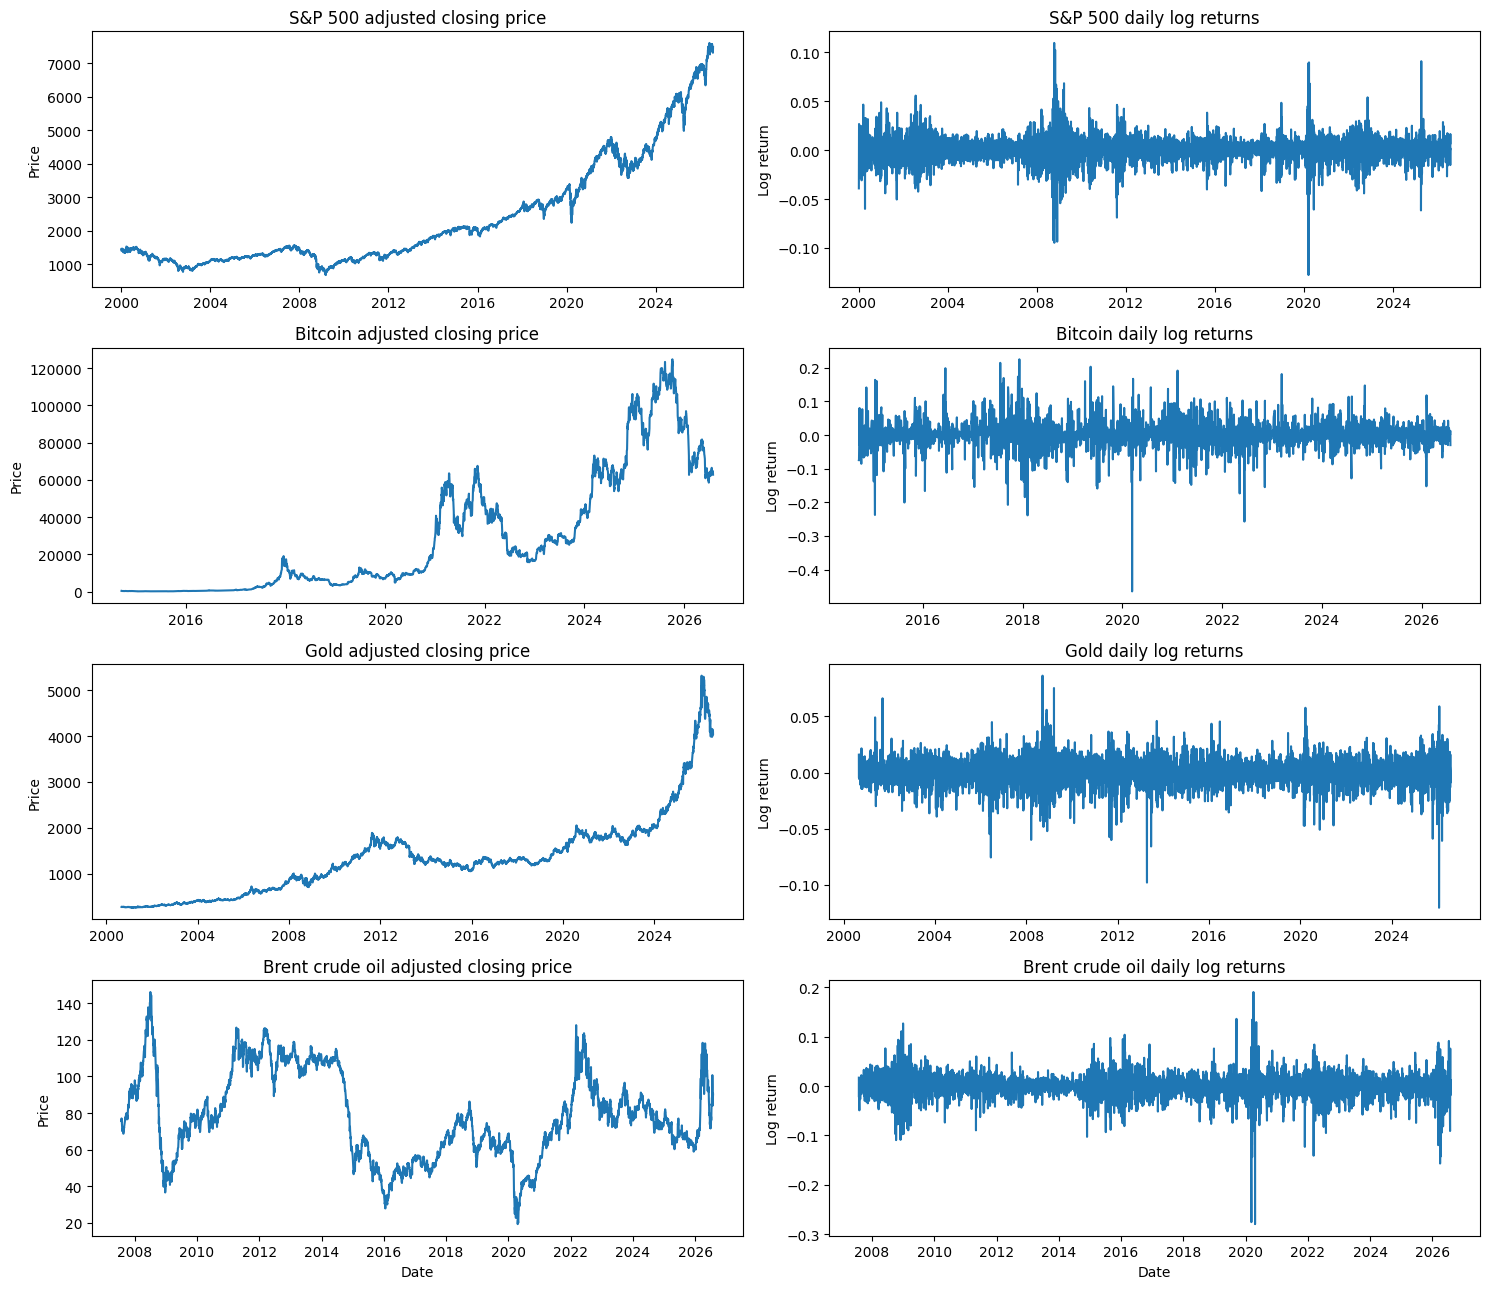

In [ ]:
fig, axes = plt.subplots(len(assets), 2, figsize=(15, 13))  # create one price and one return plot per asset

for row, asset_name in enumerate(assets):  # move through each asset one row at a time
    axes[row, 0].plot(prices[asset_name].index, prices[asset_name].values)  # plot the historical price series
    axes[row, 0].set_title(f"{asset_name} adjusted closing price")  # add the price-plot title
    axes[row, 0].set_ylabel("Price")  # label the price axis

    axes[row, 1].plot(returns[asset_name].index, returns[asset_name].values)  # plot the daily log-return series
    axes[row, 1].set_title(f"{asset_name} daily log returns")  # add the return-plot title
    axes[row, 1].set_ylabel("Log return")  # label the return axis

for axis in axes[-1]:  # use the bottom row of plots
    axis.set_xlabel("Date")  # label the horizontal axis with date

plt.tight_layout()  # prevent titles and labels from overlapping
plt.savefig(results_dir / "01_real_prices_and_returns.png",  # save a 300 dpi dissertation figure
            dpi=300, bbox_inches="tight")  # save a high-resolution dissertation figure
plt.show()  # display the figure

### Initial Observation

*The return plots show that volatility changes over time rather than remaining constant. Large movements tend to appear in periods, and Bitcoin has visibly larger return movements than the other assets. These plots give an initial indication of volatility clustering and heavy-tailed behaviour, which are examined more formally later.*

## 4. Train, Validation and Test Periods

Here I split each time series in chronological order without shuffling. The earliest 70% is used for training, the next 15% for validation and the final 15% for testing. Keeping the order of the observations prevents future data from entering the training period and leaves the latest part of each series for final evaluation.

In [ ]:
def chronological_split(series):  # split a series in time order without shuffling
    n = len(series)  # total number of observations
    train_end = int(n * train_ratio)  # position where the training period ends
    validation_end = int(n * (train_ratio + validation_ratio))  # position where validation ends

    train = series.iloc[:train_end].copy()  # earliest 70% of observations
    validation = series.iloc[train_end:validation_end].copy()  # following 15% of observations
    test = series.iloc[validation_end:].copy()  # final 15% of observations

    return train, validation, test  # return the three chronological periods


return_splits = {}  # store return splits for each asset
price_splits = {}  # store price splits for each asset

for asset_name in assets:  # repeat the split for every asset
    train_r, validation_r, test_r = chronological_split(returns[asset_name])  # split the returns
    train_p, validation_p, test_p = chronological_split(prices[asset_name])  # split the prices

    return_splits[asset_name] = {  # store the return periods
        "train": train_r,
        "validation": validation_r,
        "test": test_r,
    }

    price_splits[asset_name] = {  # store the price periods
        "train": train_p,
        "validation": validation_p,
        "test": test_p,
    }

    print(  # show the number of returns in each period
        asset_name,
        "| train:", len(train_r),
        "| validation:", len(validation_r),
        "| test:", len(test_r),
    )

S&P 500 | train: 4678 | validation: 1002 | test: 1003
Bitcoin | train: 2167 | validation: 465 | test: 465
Gold | train: 4551 | validation: 975 | test: 976
Brent crude oil | train: 3310 | validation: 709 | test: 710


## 5. Prepare Return-Space and Relative Log-Price Data

Here I prepare the two data representations used by the diffusion models. The return-space model uses standardised log-return windows, while the final Score-SDE uses relative log-price paths that start at zero. All scaling values are estimated from the training data only, so the validation and test periods do not affect the model inputs.

In [ ]:
def make_windows(values, length, stride):  # create overlapping fixed-length windows
    values = np.asarray(values, dtype=np.float32).reshape(-1)  # convert the data into one numeric vector
    windows = []  # store all created windows

    for start in range(0, len(values) - length + 1, stride):  # move through the series using the chosen stride
        windows.append(values[start:start + length])  # keep one consecutive fixed-length segment

    return np.asarray(windows, dtype=np.float32)  # return all windows as a numeric array


prepared = {}  # store the prepared data for each asset

for asset_name in assets:  # prepare each asset separately
    train_returns = return_splits[asset_name]["train"]  # training return series
    validation_returns = return_splits[asset_name]["validation"]  # validation return series
    test_returns = return_splits[asset_name]["test"]  # test return series

    return_mean = float(train_returns.mean())  # calculate return mean from training data only
    return_std = float(train_returns.std())  # calculate return standard deviation from training data only

    train_return_scaled = (train_returns - return_mean) / return_std  # standardise training returns
    validation_return_scaled = (validation_returns - return_mean) / return_std  # standardise validation returns using training values
    test_return_scaled = (test_returns - return_mean) / return_std  # standardise test returns using training values

    train_return_windows = make_windows(
        train_return_scaled.values, window_length, window_stride
    )  # create training return windows

    validation_return_windows = make_windows(
        validation_return_scaled.values, window_length, window_stride
    )  # create validation return windows

    test_return_windows = make_windows(
        test_return_scaled.values, window_length, window_stride
    )  # create test return windows


    def relative_log_price_windows(close_series):  # convert prices into relative log-price paths
        log_price = np.log(close_series.values.astype(np.float64))  # convert prices into log prices
        raw = make_windows(log_price, window_length + 1, window_stride)  # use 129 prices to obtain 128 returns
        return raw - raw[:, :1]  # shift every path so that it starts at zero


    train_paths = relative_log_price_windows(
        price_splits[asset_name]["train"]
    )  # create training log-price paths

    validation_paths = relative_log_price_windows(
        price_splits[asset_name]["validation"]
    )  # create validation log-price paths

    test_paths = relative_log_price_windows(
        price_splits[asset_name]["test"]
    )  # create test log-price paths


    path_scale = float(np.std(train_paths))  # calculate path scale from training paths only


    prepared[asset_name] = {  # store all prepared data for this asset
        "return_mean": return_mean,
        "return_std": return_std,
        "train_return_windows": train_return_windows,
        "validation_return_windows": validation_return_windows,
        "test_return_windows": test_return_windows,
        "real_test_returns": test_returns.values.astype(np.float32),
        "path_scale": path_scale,
        "train_path_windows": (train_paths / path_scale).astype(np.float32),
        "validation_path_windows": (validation_paths / path_scale).astype(np.float32),
        "test_path_windows": (test_paths / path_scale).astype(np.float32),
    }


    print(  # show the number and length of training windows
        asset_name,
        "| return windows:", train_return_windows.shape,
        "| relative log-price windows:",
        prepared[asset_name]["train_path_windows"].shape,
    )

S&P 500 | return windows: (4551, 128) | relative log-price windows: (4550, 129)
Bitcoin | return windows: (2040, 128) | relative log-price windows: (2040, 129)
Gold | return windows: (4424, 128) | relative log-price windows: (4424, 129)
Brent crude oil | return windows: (3183, 128) | relative log-price windows: (3183, 129)


## 6. VE Noise Schedule and Forward Diffusion

Here I define the variance-exploding (VE) noise schedule. The forward diffusion process gradually adds Gaussian noise to a clean financial path. The example below uses one real S&P 500 relative log-price path and shows how its original structure becomes less visible as the diffusion time moves from \(t=0\) towards \(t=1\).

In [ ]:
def sigma(t):  # define the ve noise level at diffusion time t
    return sigma_min * (sigma_max / sigma_min) ** t  # increase the noise level with diffusion time


def diffusion_coefficient(t):  # define the diffusion strength used by the ve-sde
    log_ratio = np.log(sigma_max / sigma_min)  # constant determined by the noise range
    return sigma(t) * np.sqrt(2.0 * log_ratio)  # calculate the ve-sde diffusion coefficient

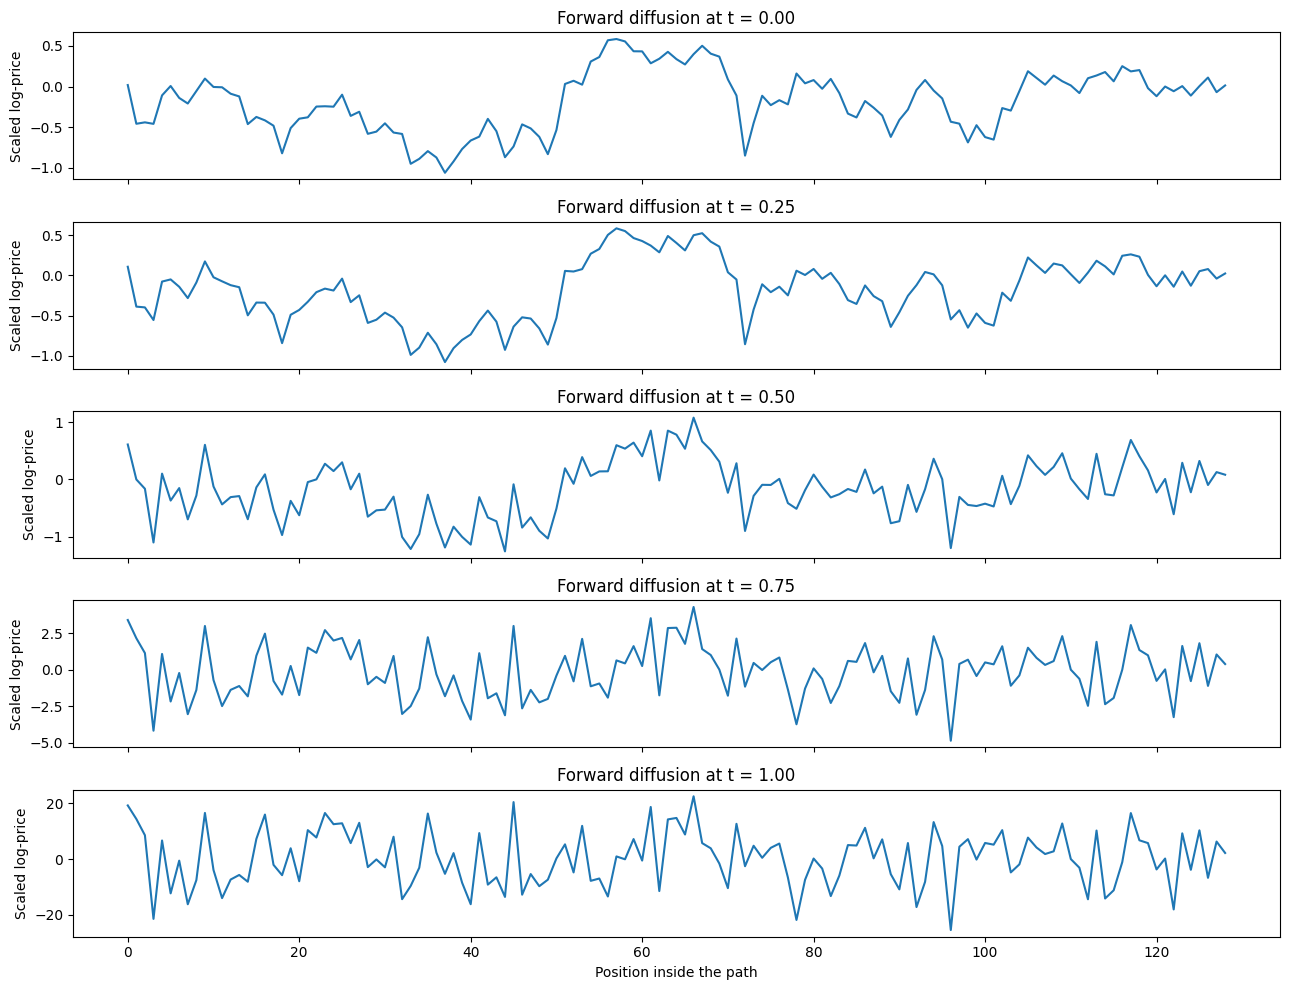

In [ ]:
x0 = torch.tensor(prepared["S&P 500"]["train_path_windows"][0], dtype=torch.float32)  # one clean path
z = torch.randn_like(x0)  # fixed gaussian corruption for the illustration
times = [0.0, 0.25, 0.50, 0.75, 1.0]

fig, axes = plt.subplots(len(times), 1, figsize=(13, 10), sharex=True)

for axis, time_value in zip(axes, times):
    t = torch.tensor(time_value, dtype=torch.float32)
    xt = x0 + sigma(t) * z  # apply forward ve perturbation

    axis.plot(xt.numpy())
    axis.set_title(f"Forward diffusion at t = {time_value:.2f}")
    axis.set_ylabel("Scaled log-price")

axes[-1].set_xlabel("Position inside the path")

plt.tight_layout()
plt.savefig(results_dir / "02_forward_diffusion.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### What the Forward Diffusion Plot Shows

*At small diffusion times the financial path is still easy to recognise. As \(t\) increases, the Gaussian noise becomes larger and the original structure gradually disappears. At \(t=1\), the path is dominated by noise. The reverse-SDE generation later tries to move in the opposite direction.*

## 7. Score Network

Here I define the neural network used by the diffusion models. It is a residual one-dimensional convolutional network. The network receives the noisy financial path together with the diffusion time and learns to predict the Gaussian noise that was added to the clean path.

In [ ]:
class ResidualBlock(nn.Module):  # residual convolution block used by the score network
    def __init__(self, channels):
        super().__init__()

        self.conv1 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)  # first local temporal filter
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)  # second local temporal filter
        self.activation = nn.SiLU()  # smooth non-linearity

    def forward(self, x):
        residual = x  # keep the original features
        x = self.activation(self.conv1(x))  # learn the first transformation
        x = self.conv2(x)  # learn the second transformation
        return self.activation(x + residual)  # add the shortcut connection


class ScoreNetwork(nn.Module):  # time-conditioned 1d cnn used to predict diffusion noise
    def __init__(self, channels=64, blocks=4):
        super().__init__()

        self.input_layer = nn.Conv1d(2, channels, kernel_size=5, padding=2)  # read data and diffusion time
        self.blocks = nn.ModuleList([ResidualBlock(channels) for _ in range(blocks)])  # residual temporal layers
        self.output_layer = nn.Conv1d(channels, 1, kernel_size=5, padding=2)  # return one noise estimate per time point
        self.activation = nn.SiLU()  # activation used after the input layer

    def forward(self, x, t):
        x_channel = x.unsqueeze(1)  # add a channel dimension to the time series
        t_channel = t.unsqueeze(-1).expand(-1, 1, x.shape[1])  # repeat diffusion time across the path
        h = torch.cat([x_channel, t_channel], dim=1)  # combine current sample and current time
        h = self.activation(self.input_layer(h))  # create the first hidden representation

        for block in self.blocks:  # pass through all residual blocks
            h = block(h)

        return self.output_layer(h).squeeze(1)  # return predicted gaussian noise

## 8. Training Loss and Fixed Validation

Here I define the denoising loss used to train the score network. Training uses randomly sampled diffusion times and Gaussian noise. For validation, the same corrupted validation examples are reused at each check so that changes in validation loss reflect changes in the model rather than a completely new random validation sample.

In [ ]:
def training_loss(model, batch):  # calculate the denoising loss for one training batch
    t = torch.rand(batch.shape[0], 1, device=device)  # random diffusion times for training
    sigma_t = sigma(t)  # corresponding noise levels
    true_noise = torch.randn_like(batch)  # random gaussian training corruption
    noisy_batch = batch + sigma_t * true_noise  # create noisy training samples
    predicted_noise = model(noisy_batch, t)  # estimate the added noise
    return torch.mean((predicted_noise - true_noise) ** 2)  # denoising objective

def make_fixed_validation(validation_tensor, validation_seed):  # create one fixed corrupted validation sample
    n = min(1024, len(validation_tensor))  # use a stable validation sample size
    batch = validation_tensor[:n]  # always use the same validation windows

    generator = torch.Generator(device=device)
    generator.manual_seed(validation_seed)  # keep validation randomness fixed

    t = torch.rand((n, 1), generator=generator, device=device)  # fixed diffusion times
    t = 0.001 + 0.998 * t  # avoid exact endpoints
    true_noise = torch.randn(batch.shape, generator=generator, device=device)  # fixed gaussian perturbations
    noisy_batch = batch + sigma(t) * true_noise  # fixed noisy validation samples

    return noisy_batch, t, true_noise

@torch.no_grad()
def fixed_validation_loss(model, fixed_validation):  # evaluate the same validation corruption at each check
    noisy_batch, t, true_noise = fixed_validation  # reuse the same validation data
    model.eval()
    predicted_noise = model(noisy_batch, t)  # estimate the fixed perturbations
    return float(torch.mean((predicted_noise - true_noise) ** 2).item())

def train_model(train_windows, validation_windows, name, run_seed):
    set_seed(run_seed)  # make model initialisation and training repeatable

    train_tensor = torch.tensor(train_windows, dtype=torch.float32, device=device)
    validation_tensor = torch.tensor(validation_windows, dtype=torch.float32, device=device)

    model = ScoreNetwork().to(device)  # keep the current final architecture
    optimiser = optim.Adam(model.parameters(), lr=learning_rate)  # keep the current optimiser setup

    fixed_validation = make_fixed_validation(validation_tensor, run_seed + 10000)  # validation never changes between checks

    best_state = None
    best_validation = np.inf
    checks_without_improvement = 0
    recent_losses = []
    history = []

    for step in range(1, max_training_steps + 1):
        model.train()

        index = torch.randint(0, len(train_tensor), (batch_size,), device=device)  # random training mini-batch
        batch = train_tensor[index]

        loss = training_loss(model, batch)  # stochastic training objective

        optimiser.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimiser.step()

        recent_losses.append(float(loss.item()))

        if step % validation_every == 0:
            train_value = float(np.mean(recent_losses[-validation_every:]))
            validation_value = fixed_validation_loss(model, fixed_validation)  # compare checkpoints fairly

            history.append({
                "step": step,
                "train_loss": train_value,
                "validation_loss": validation_value,
            })

            print(
                name,
                "| step", step,
                "| train", round(train_value, 5),
                "| validation", round(validation_value, 5),
            )

            if validation_value < best_validation:
                best_validation = validation_value
                best_state = copy.deepcopy(model.state_dict())  # keep an independent copy of the best validation weights
                checks_without_improvement = 0
            else:
                checks_without_improvement += 1

            if checks_without_improvement >= early_stopping_checks:  # stop when validation has not improved for the chosen patience
                print(name, "| early stopping at step", step)
                break

    if best_state is not None:
        model.load_state_dict(best_state)  # restore the most reliable validation checkpoint

    return model, pd.DataFrame(history)

## 9. Train the Two Diffusion Representations

Here I train one return-space VE model and one relative log-price Score-SDE for each asset. Both models use the same network architecture and main training settings. Saved checkpoints are loaded when they already exist so that completed training does not have to be repeated.

In [ ]:
checkpoint_dir = Path(SAVE_DIR) / "model_checkpoints"  # keep trained weights permanently in google drive
checkpoint_dir.mkdir(parents=True, exist_ok=True)

return_ve_models = {}
final_score_models = {}

return_ve_histories = {}
final_score_histories = {}

def safe_asset_name(asset_name):
    return (
        asset_name.lower()
        .replace(" ", "_")
        .replace("&", "and")
        .replace("/", "_")
    )

for asset_index, asset_name in enumerate(assets):
    baseline_seed = seed + 100 * asset_index + 1
    final_seed = seed + 100 * asset_index + 2

    safe_name = safe_asset_name(asset_name)
    baseline_path = checkpoint_dir / f"{safe_name}_return_ve.pt"
    final_path = checkpoint_dir / f"{safe_name}_relative_log_price_score_sde.pt"

    baseline_model = ScoreNetwork().to(device)
    final_model = ScoreNetwork().to(device)

    if baseline_path.exists():
        baseline_model.load_state_dict(torch.load(baseline_path, map_location=device))  # reuse saved baseline weights
        baseline_history = pd.DataFrame()
        print(asset_name, "| loaded saved return-space ve model")
    else:
        print("\ntraining return-space ve baseline for", asset_name)

        baseline_model, baseline_history = train_model(
            prepared[asset_name]["train_return_windows"],
            prepared[asset_name]["validation_return_windows"],
            f"{asset_name} return VE",
            baseline_seed,
        )

        torch.save(baseline_model.state_dict(), baseline_path)  # save weights so training is not repeated later
        print(asset_name, "| saved return-space ve checkpoint")

    if final_path.exists():
        final_model.load_state_dict(torch.load(final_path, map_location=device))  # reuse saved final score-sde weights
        final_history = pd.DataFrame()
        print(asset_name, "| loaded saved relative-log-price score-sde")
    else:
        print("\ntraining final relative-log-price score-sde for", asset_name)

        final_model, final_history = train_model(
            prepared[asset_name]["train_path_windows"],
            prepared[asset_name]["validation_path_windows"],
            f"{asset_name} relative log-price Score-SDE",
            final_seed,
        )

        torch.save(final_model.state_dict(), final_path)  # save weights so training is not repeated later
        print(asset_name, "| saved relative-log-price score-sde checkpoint")

    return_ve_models[asset_name] = baseline_model
    final_score_models[asset_name] = final_model

    return_ve_histories[asset_name] = baseline_history
    final_score_histories[asset_name] = final_history

S&P 500 | loaded saved return-space ve model
S&P 500 | loaded saved relative-log-price score-sde
Bitcoin | loaded saved return-space ve model
Bitcoin | loaded saved relative-log-price score-sde
Gold | loaded saved return-space ve model
Gold | loaded saved relative-log-price score-sde
Brent crude oil | loaded saved return-space ve model
Brent crude oil | loaded saved relative-log-price score-sde


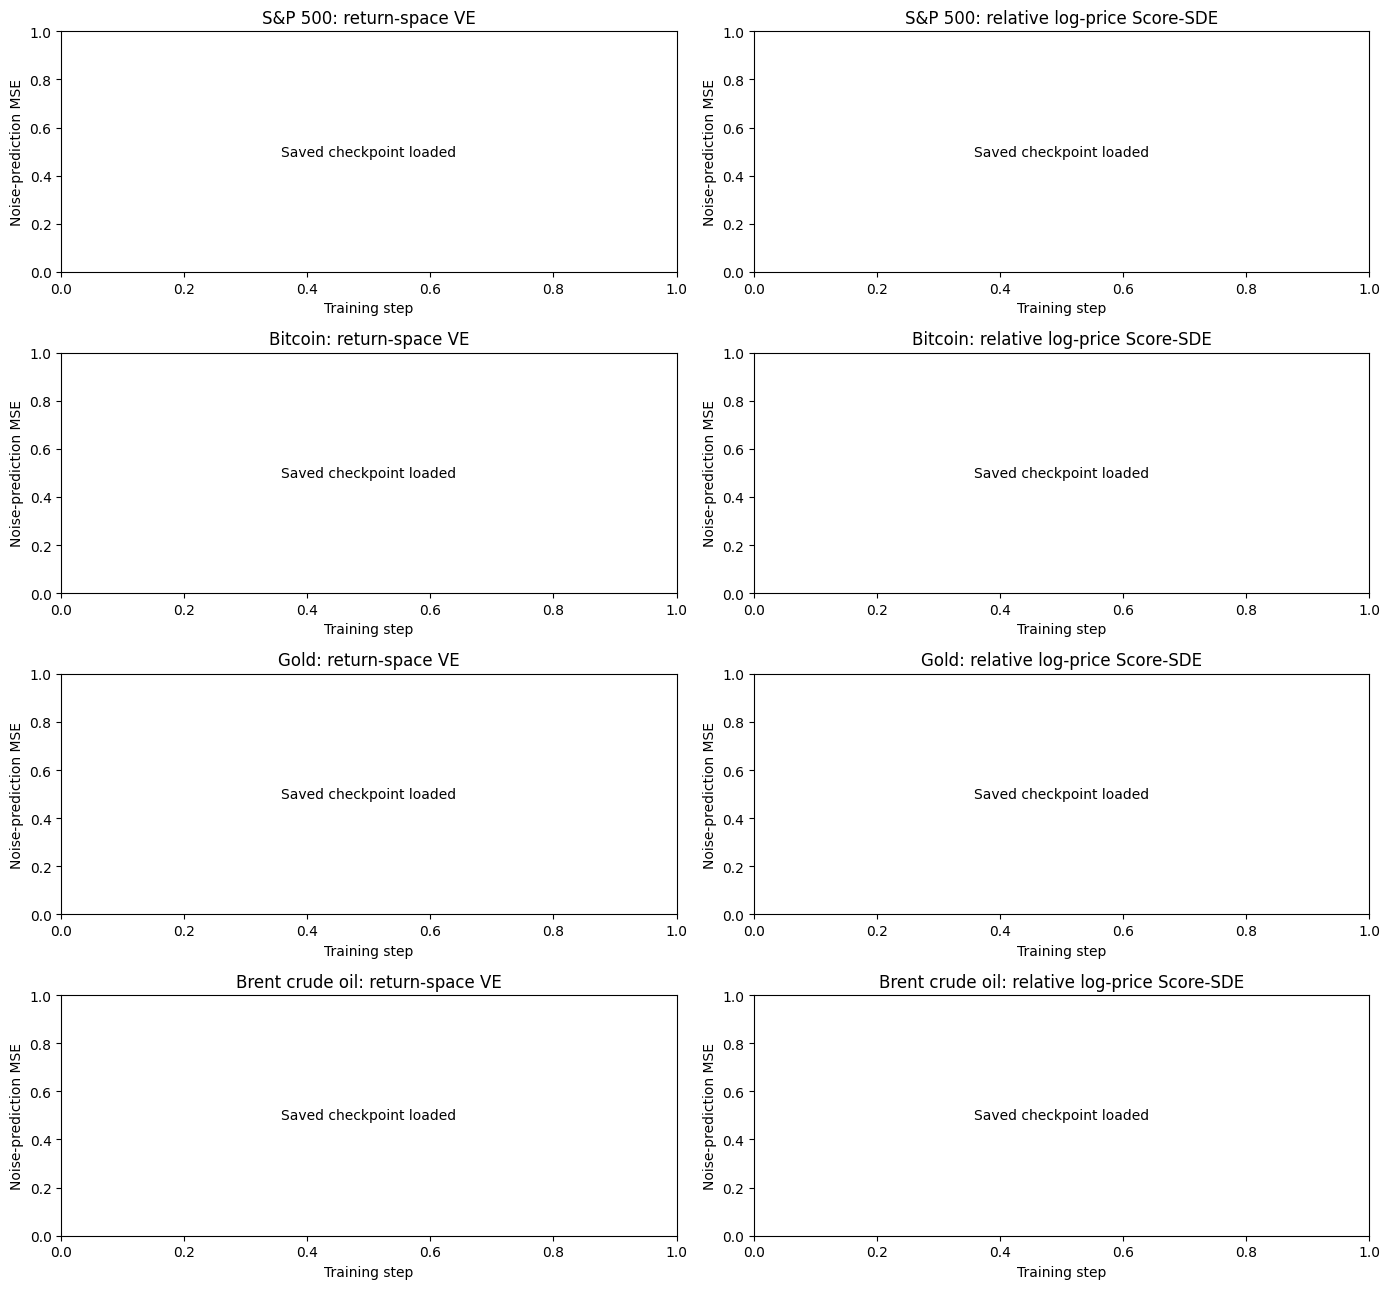

In [ ]:
fig, axes = plt.subplots(len(assets), 2, figsize=(14, 13))  # create one price and one return plot per asset

for row, asset_name in enumerate(assets):
    baseline_history = return_ve_histories[asset_name]
    final_history = final_score_histories[asset_name]

    if len(baseline_history):
        axes[row, 0].plot(baseline_history["step"], baseline_history["train_loss"], label="Training")
        axes[row, 0].plot(baseline_history["step"], baseline_history["validation_loss"], label="Fixed validation")
        axes[row, 0].legend()
    else:
        axes[row, 0].text(0.5, 0.5, "Saved checkpoint loaded", ha="center", va="center")

    axes[row, 0].set_title(f"{asset_name}: return-space VE")
    axes[row, 0].set_xlabel("Training step")
    axes[row, 0].set_ylabel("Noise-prediction MSE")

    if len(final_history):
        axes[row, 1].plot(final_history["step"], final_history["train_loss"], label="Training")
        axes[row, 1].plot(final_history["step"], final_history["validation_loss"], label="Fixed validation")
        axes[row, 1].legend()
    else:
        axes[row, 1].text(0.5, 0.5, "Saved checkpoint loaded", ha="center", va="center")

    axes[row, 1].set_title(f"{asset_name}: relative log-price Score-SDE")
    axes[row, 1].set_xlabel("Training step")
    axes[row, 1].set_ylabel("Noise-prediction MSE")

plt.tight_layout()
plt.savefig(results_dir / "03_training_and_fixed_validation.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Note on the Training-Loss Figure

*In this executed notebook the saved model checkpoints were loaded, so the original training histories were not available in memory. The panels therefore show that a saved checkpoint was loaded rather than a training curve. This placeholder figure should not be used as evidence in the dissertation unless the models are trained again and the actual loss history is saved.*

## 10. Reverse-SDE Generation

Here I use the trained diffusion models to generate new financial paths from Gaussian noise. The reverse SDE moves gradually from the noisy starting sample towards a generated path. The final experiment produces 5,000 paths per asset, in batches of 500 to keep GPU memory use manageable.

In [ ]:
@torch.no_grad()
def reverse_sample(  # generate samples by solving the reverse sde
    model,
    sample_length,
    number_of_samples,
    reverse_steps,
    sample_seed,
    collect_stability=False,
    asset_name=None,
    model_name=None,
    batch_number=None,
):
    set_seed(sample_seed)  # make the sampling run repeatable
    model.eval()

    x = torch.randn(number_of_samples, sample_length, device=device) * sigma_max  # start from terminal gaussian noise
    dt = 1.0 / reverse_steps  # reverse-time step size
    stability_rows = []

    for step in range(reverse_steps):
        t_value = max(1.0 - step * dt, 1e-4)  # move from one towards zero
        t = torch.full((number_of_samples, 1), t_value, device=device)

        sigma_t = sigma(t)
        g_t = diffusion_coefficient(t)

        predicted_noise = model(x, t)  # estimate current noise
        score = -predicted_noise / sigma_t  # convert noise prediction to score
        mean_x = x + (g_t ** 2) * score * dt  # reverse drift

        if step < reverse_steps - 1:
            x = mean_x + g_t * np.sqrt(dt) * torch.randn_like(x)  # euler-maruyama stochastic update
        else:
            x = mean_x

        if collect_stability:
            nan_count = int(torch.isnan(x).sum().item())  # count nan values before applying protection
            posinf_count = int(torch.isposinf(x).sum().item())  # count positive infinities
            neginf_count = int(torch.isneginf(x).sum().item())  # count negative infinities

            if nan_count or posinf_count or neginf_count:
                stability_rows.append({
                    "Asset": asset_name,
                    "Model": model_name,
                    "Batch": batch_number,
                    "Reverse step": step + 1,
                    "Diffusion time": t_value,
                    "NaN count": nan_count,
                    "+Inf count": posinf_count,
                    "-Inf count": neginf_count,
                })

        x = torch.nan_to_num(x, nan=0.0, posinf=50.0, neginf=-50.0)  # keep the existing numerical safeguard

    samples = x.cpu().numpy()

    if collect_stability:
        return samples, stability_rows

    return samples

def reverse_sample_batched(  # generate samples by solving the reverse sde
    model,
    sample_length,
    total_samples,
    reverse_steps,
    batch_size_samples,
    sample_seed,
    collect_stability=False,
    asset_name=None,
    model_name=None,
):
    batches = []
    stability_rows = []
    completed = 0
    batch_number = 0

    while completed < total_samples:  # continue until all samples are generated
        current_batch = min(batch_size_samples, total_samples - completed)

        result = reverse_sample(
            model,
            sample_length,
            current_batch,
            reverse_steps,
            sample_seed + batch_number,
            collect_stability=collect_stability,
            asset_name=asset_name,
            model_name=model_name,
            batch_number=batch_number + 1,
        )

        if collect_stability:
            batch, batch_stability = result
            stability_rows.extend(batch_stability)
        else:
            batch = result

        batches.append(batch)
        completed += current_batch
        batch_number += 1

        print("generated", completed, "of", total_samples)

    samples = np.concatenate(batches, axis=0)

    if collect_stability:
        return samples, stability_rows

    return samples

In [ ]:
return_ve_generated = {}
score_generated_returns = {}
stability_events = []

for asset_index, asset_name in enumerate(assets):
    print("\ngenerating return-space ve paths for", asset_name)

    baseline_scaled = reverse_sample_batched(
        return_ve_models[asset_name],
        window_length,
        n_generated,
        n_reverse_steps,
        generation_batch_size,
        seed + 1000 + 20 * asset_index,
    )

    return_ve_generated[asset_name] = (
        baseline_scaled * prepared[asset_name]["return_std"]
        + prepared[asset_name]["return_mean"]
    )

    print("\ngenerating final score-sde paths for", asset_name)

    generated_scaled_paths, asset_stability = reverse_sample_batched(
        final_score_models[asset_name],
        window_length + 1,
        n_generated,
        n_reverse_steps,
        generation_batch_size,
        seed + 2000 + 20 * asset_index,
        collect_stability=True,
        asset_name=asset_name,
        model_name="Score-SDE",
    )

    stability_events.extend(asset_stability)

    generated_paths = generated_scaled_paths * prepared[asset_name]["path_scale"]
    generated_paths = generated_paths - generated_paths[:, :1]
    score_generated_returns[asset_name] = np.diff(generated_paths, axis=1)  # convert generated relative log prices back to returns

    print(asset_name, "| score-sde generated:", score_generated_returns[asset_name].shape)

stability_columns = [
    "Asset",
    "Model",
    "Batch",
    "Reverse step",
    "Diffusion time",
    "NaN count",
    "+Inf count",
    "-Inf count",
]

stability_events_table = pd.DataFrame(stability_events, columns=stability_columns)

if len(stability_events_table) == 0:
    print("stability check: zero nan or inf values were produced before torch.nan_to_num")
else:
    display(stability_events_table)
    print("stability check: numerical-instability events were detected")

stability_events_table.to_csv(results_dir / "04_score_sde_stability_events.csv", index=False)  # save the numerical results as csv
stability_events_table.to_csv(Path(SAVE_DIR) / "score_sde_stability_events.csv", index=False)  # save the numerical results as csv


generating return-space ve paths for S&P 500
generated 500 of 5000
generated 1000 of 5000
generated 1500 of 5000
generated 2000 of 5000
generated 2500 of 5000
generated 3000 of 5000
generated 3500 of 5000
generated 4000 of 5000
generated 4500 of 5000
generated 5000 of 5000

generating final score-sde paths for S&P 500
generated 500 of 5000
generated 1000 of 5000
generated 1500 of 5000
generated 2000 of 5000
generated 2500 of 5000
generated 3000 of 5000
generated 3500 of 5000
generated 4000 of 5000
generated 4500 of 5000
generated 5000 of 5000
S&P 500 | score-sde generated: (5000, 128)

generating return-space ve paths for Bitcoin
generated 500 of 5000
generated 1000 of 5000
generated 1500 of 5000
generated 2000 of 5000
generated 2500 of 5000
generated 3000 of 5000
generated 3500 of 5000
generated 4000 of 5000
generated 4500 of 5000
generated 5000 of 5000

generating final score-sde paths for Bitcoin
generated 500 of 5000
generated 1000 of 5000
generated 1500 of 5000
generated 2000 of 

### Generation Check

*All final Score-SDE outputs have shape \(5000\times128\), giving 5,000 generated 128-day return paths per asset. The stability check reports zero NaN or Inf values before numerical replacement, so the later poor Bitcoin result is not caused by a simple numerical overflow.*

In [ ]:
GENERATED_DIR = os.path.join(SAVE_DIR, "generated")
os.makedirs(GENERATED_DIR, exist_ok=True)

for asset_name, generated_returns in score_generated_returns.items():

    safe_name = (
        asset_name.replace(" ", "_")
        .replace("&", "and")
        .replace("/", "_")
    )

    np.save(  # save the generated array
        os.path.join(
            GENERATED_DIR,
            f"{safe_name}_score_sde_generated_returns.npy"
        ),
        generated_returns
    )

    print(asset_name, "| saved:", generated_returns.shape)

print("All Score-SDE generated returns saved to Google Drive.")

S&P 500 | saved: (5000, 128)
Bitcoin | saved: (5000, 128)
Gold | saved: (5000, 128)
Brent crude oil | saved: (5000, 128)
All Score-SDE generated returns saved to Google Drive.


## 11. Ordinary GBM Benchmark

Here I fit ordinary geometric Brownian motion using the training returns only and generate 5,000 benchmark paths for each asset. GBM provides a simple reference model because it assumes Gaussian log returns with constant volatility.

In [ ]:
def estimate_gbm_parameters(training_log_returns):  # estimate gbm drift and volatility from training returns
    training_log_returns = np.asarray(training_log_returns, dtype=np.float64)
    sigma_hat = float(np.std(training_log_returns, ddof=1))  # daily gbm volatility
    mean_log_return = float(np.mean(training_log_returns))  # observed daily log-return mean
    mu_hat = mean_log_return + 0.5 * sigma_hat ** 2  # implied gbm drift
    return mu_hat, sigma_hat

def generate_gbm_return_paths(mu_hat, sigma_hat, number_of_paths, length, gbm_seed):
    rng = np.random.default_rng(gbm_seed)  # independent reproducible benchmark generator
    z = rng.standard_normal((number_of_paths, length))  # brownian innovations
    drift = mu_hat - 0.5 * sigma_hat ** 2  # daily log-return drift
    return drift + sigma_hat * z  # gbm log returns

gbm_parameters = {}
gbm_generated_returns = {}

for asset_index, asset_name in enumerate(assets):
    training_returns = return_splits[asset_name]["train"].values  # estimate parameters from training data only
    mu_hat, sigma_hat = estimate_gbm_parameters(training_returns)

    gbm_parameters[asset_name] = {
        "mu": mu_hat,
        "sigma": sigma_hat,
    }

    gbm_generated_returns[asset_name] = generate_gbm_return_paths(
        mu_hat,
        sigma_hat,
        n_generated,
        window_length,
        seed + 3000 + asset_index,
    )

gbm_parameter_table = pd.DataFrame(gbm_parameters).T
display(gbm_parameter_table.round(8))
gbm_parameter_table.to_csv(results_dir / "04_gbm_training_parameters.csv")  # save the numerical results as csv

,mu,sigma
S&P 500,0.000217,0.012069
Bitcoin,0.002684,0.045086
Gold,0.000393,0.011239
Brent crude oil,0.000164,0.024374


## 12. GARCH(1,1)-t Benchmark

Here I fit GARCH(1,1) with Student-\(t\) innovations to the training returns and generate 5,000 benchmark paths for each asset. GARCH is a stronger financial benchmark than GBM because it allows volatility to change over time and the Student-\(t\) innovations allow heavier tails.

In [ ]:
def fit_garch_t(training_returns):  # fit garch(1,1) with student-t innovations
    returns_percent = np.asarray(training_returns, dtype=np.float64) * 100.0  # percentage scale improves numerical fitting

    model = arch_model(  # specify the garch(1,1)-t benchmark
        returns_percent,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="StudentsT",
        rescale=False,
    )

    result = model.fit(disp="off")  # estimate parameters using training data only
    return result

def simulate_garch_t_paths(fitted_result, number_of_paths, length, simulation_seed):
    params = fitted_result.params

    mu = float(params["mu"]) if "mu" in params.index else 0.0  # conditional mean in percent returns
    omega = float(params["omega"])  # garch constant
    alpha = float(params["alpha[1]"])  # reaction to previous shocks
    beta = float(params["beta[1]"])  # volatility persistence
    nu = float(params["nu"])  # student-t degrees of freedom

    rng = np.random.default_rng(simulation_seed)
    paths = np.empty((number_of_paths, length), dtype=np.float64)

    persistence = alpha + beta

    if persistence < 0.999:
        initial_variance = omega / max(1.0 - persistence, 1e-8)  # stationary long-run variance
    else:
        initial_variance = float(np.var(fitted_result.model.y, ddof=1))  # fallback for near-integrated estimates

    t_scale = np.sqrt((nu - 2.0) / nu) if nu > 2.0 else 1.0  # standardise student-t innovations to unit variance

    for path_index in range(number_of_paths):
        variance = max(initial_variance, 1e-10)
        previous_shock = 0.0

        for t in range(length):
            variance = omega + alpha * previous_shock ** 2 + beta * variance  # update conditional variance
            variance = max(variance, 1e-10)

            z = rng.standard_t(nu) * t_scale  # heavy-tailed standardised innovation
            shock = np.sqrt(variance) * z
            paths[path_index, t] = mu + shock
            previous_shock = shock

    return paths / 100.0  # convert percentage returns back to decimal log-return scale

garch_results = {}
garch_generated_returns = {}
garch_parameter_rows = []

for asset_index, asset_name in enumerate(assets):
    fitted = fit_garch_t(return_splits[asset_name]["train"].values)  # fit only to the training period
    garch_results[asset_name] = fitted

    garch_generated_returns[asset_name] = simulate_garch_t_paths(
        fitted,
        n_generated,
        window_length,
        seed + 4000 + asset_index,
    )

    params = fitted.params

    garch_parameter_rows.append({
        "Asset": asset_name,
        "mu": params.get("mu", np.nan),
        "omega": params.get("omega", np.nan),
        "alpha[1]": params.get("alpha[1]", np.nan),
        "beta[1]": params.get("beta[1]", np.nan),
        "nu": params.get("nu", np.nan),
        "alpha + beta": params.get("alpha[1]", np.nan) + params.get("beta[1]", np.nan),  # record volatility persistence
    })

garch_parameter_table = pd.DataFrame(garch_parameter_rows).set_index("Asset")
display(garch_parameter_table.round(6))
garch_parameter_table.to_csv(results_dir / "05_garch_t_parameters.csv")  # save the numerical results as csv

,mu,omega,alpha[1],beta[1],nu,alpha + beta
Asset,,,,,,
S&P 500,0.066150,0.009557,0.102422,0.895556,6.499070,0.997978
Bitcoin,0.182873,0.338809,0.120030,0.879970,3.050954,1.000000
Gold,0.043473,0.006885,0.033016,0.962455,4.889466,0.995471
Brent crude oil,0.047280,0.038032,0.081263,0.916231,5.260194,0.997494


### GARCH Result

*The fitted GARCH persistence \(\alpha+\beta\) is very close to one for all four assets, showing highly persistent volatility. Bitcoin is at approximately \(1.000\) and also has the lowest Student-\(t\) degrees of freedom, so its fitted GARCH model has especially persistent and heavy-tailed behaviour.*

In [ ]:
generated_dir = Path(SAVE_DIR) / "generated"  # folder for generated return arrays
generated_dir.mkdir(parents=True, exist_ok=True)

for asset_name, generated_returns in garch_generated_returns.items():
    safe_name = safe_asset_name(asset_name)
    np.save(  # save the generated array
        generated_dir / f"{safe_name}_garch_t_generated_returns.npy",
        generated_returns,
    )

print("all garch-t generated returns saved to google drive")

all garch-t generated returns saved to google drive


# Financial Evaluation

The following sections compare the generated returns with the same held-out real test data. I use several measures because a model can match the overall return distribution while still getting the tails, volatility or time dependence wrong.

In [ ]:
real_test_windows = {}

for asset_name in assets:
    real_test_windows[asset_name] = (
        prepared[asset_name]["test_return_windows"] * prepared[asset_name]["return_std"]
        + prepared[asset_name]["return_mean"]
    )

## 13. Real and Artificial Paths

Here I compare one real test window with example paths from ordinary GBM, GARCH-t and the Score-SDE. This is only a visual check. A path can look realistic while still having the wrong return distribution, tail behaviour or volatility structure, so the numerical comparisons below are more important.

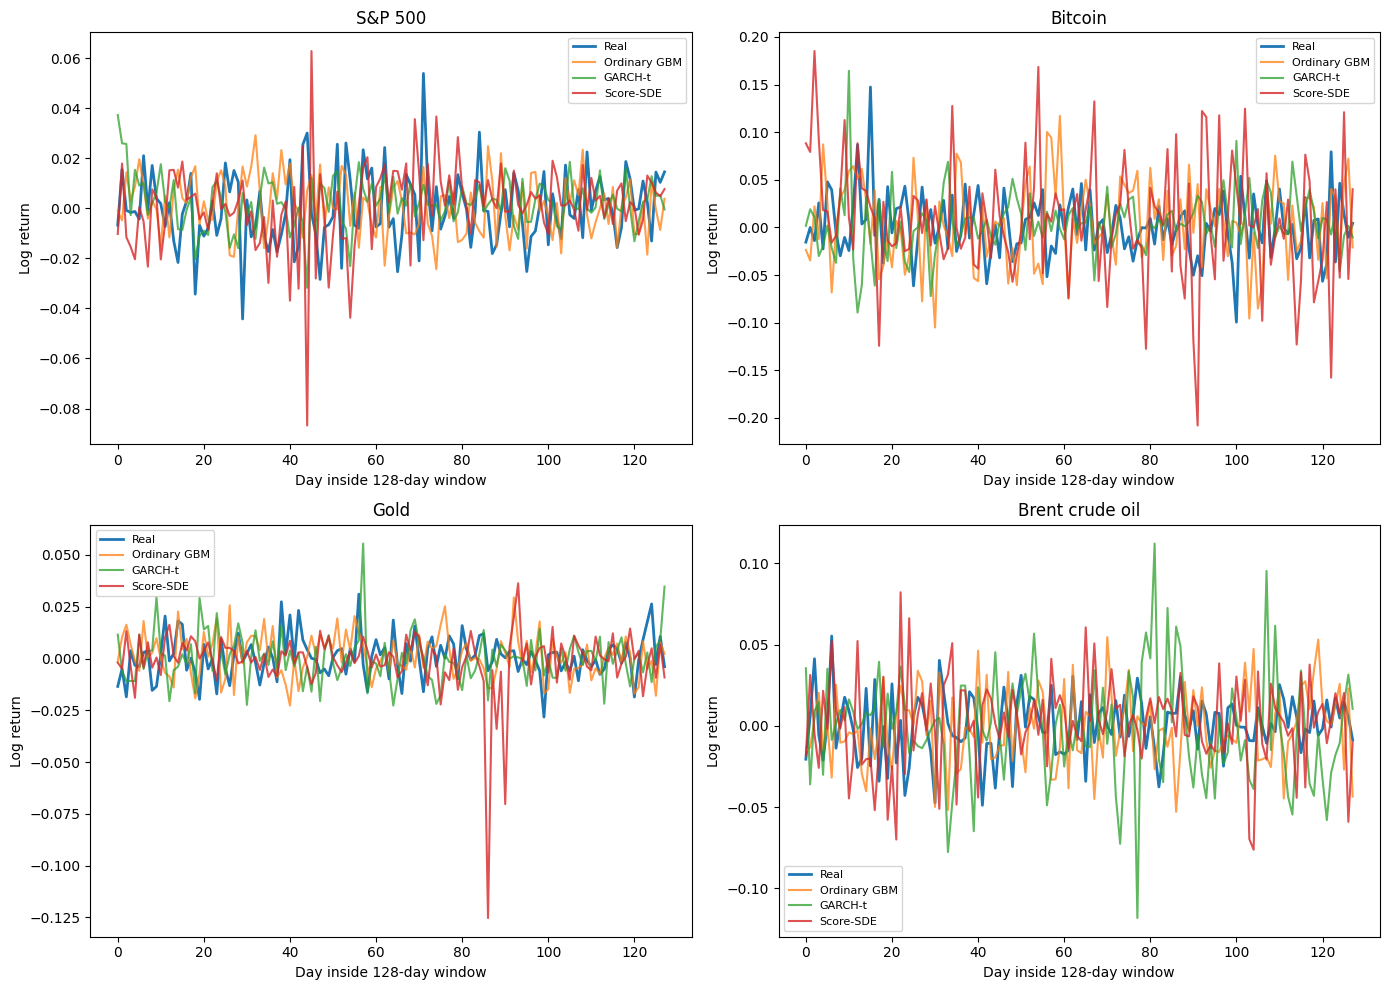

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    axis.plot(real_test_windows[asset_name][0], linewidth=2.0, label="Real")
    axis.plot(gbm_generated_returns[asset_name][0], alpha=0.75, label="Ordinary GBM")
    axis.plot(garch_generated_returns[asset_name][0], alpha=0.75, label="GARCH-t")
    axis.plot(score_generated_returns[asset_name][0], alpha=0.80, label="Score-SDE")

    axis.set_title(asset_name)
    axis.set_xlabel("Day inside 128-day window")
    axis.set_ylabel("Log return")
    axis.legend(fontsize=8)

plt.tight_layout()
plt.savefig(results_dir / "06_real_gbm_garch_score_paths.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

## 14. Return Distributions and Q-Q Plots

Here I compare the empirical distributions of real and generated daily returns. The histograms show the overall shape and spread, while the Q-Q plots compare corresponding quantiles and make tail mismatches easier to see. A closer match to the diagonal in a Q-Q plot indicates a closer distributional fit.

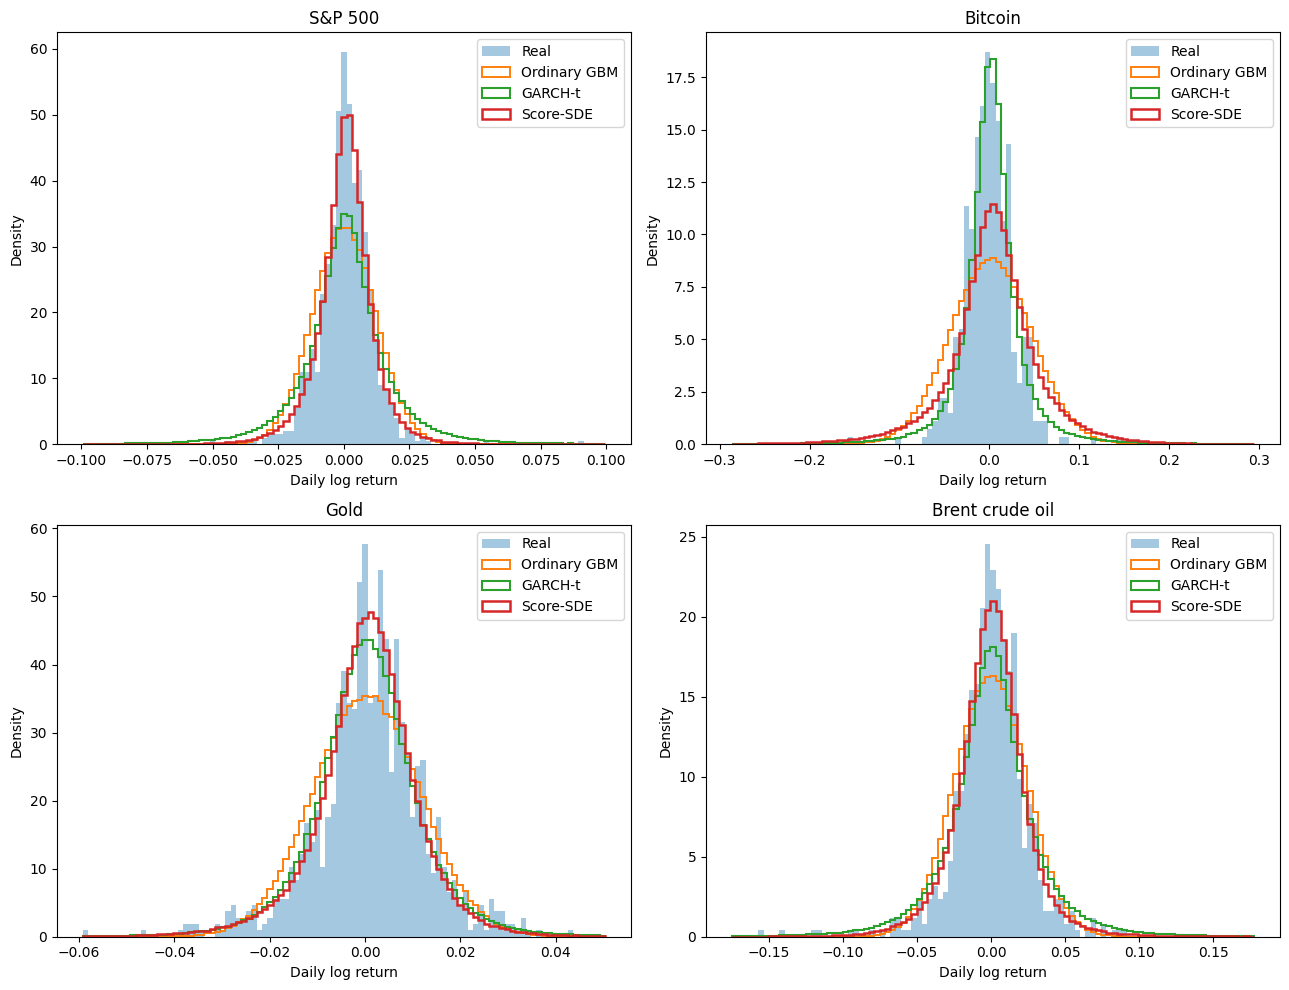

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    real = prepared[asset_name]["real_test_returns"]
    gbm = gbm_generated_returns[asset_name].reshape(-1)
    garch = garch_generated_returns[asset_name].reshape(-1)
    score = score_generated_returns[asset_name].reshape(-1)

    lower = min(
        np.quantile(real, 0.002),
        np.quantile(gbm, 0.002),
        np.quantile(garch, 0.002),
        np.quantile(score, 0.002),
    )
    upper = max(
        np.quantile(real, 0.998),
        np.quantile(gbm, 0.998),
        np.quantile(garch, 0.998),
        np.quantile(score, 0.998),
    )
    bins = np.linspace(lower, upper, 100)

    axis.hist(real, bins=bins, density=True, alpha=0.40, label="Real")
    axis.hist(gbm, bins=bins, density=True, histtype="step", linewidth=1.4, label="Ordinary GBM")
    axis.hist(garch, bins=bins, density=True, histtype="step", linewidth=1.5, label="GARCH-t")
    axis.hist(score, bins=bins, density=True, histtype="step", linewidth=1.8, label="Score-SDE")

    axis.set_title(asset_name)
    axis.set_xlabel("Daily log return")
    axis.set_ylabel("Density")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "07_return_distributions.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Distribution Plot Observation

*The S&P 500 Score-SDE distribution is relatively close to the real return distribution. Bitcoin is very different: the generated Score-SDE returns are much more spread out than the real data. Gold and Brent are closer overall, but the models differ in the centre and tails.*

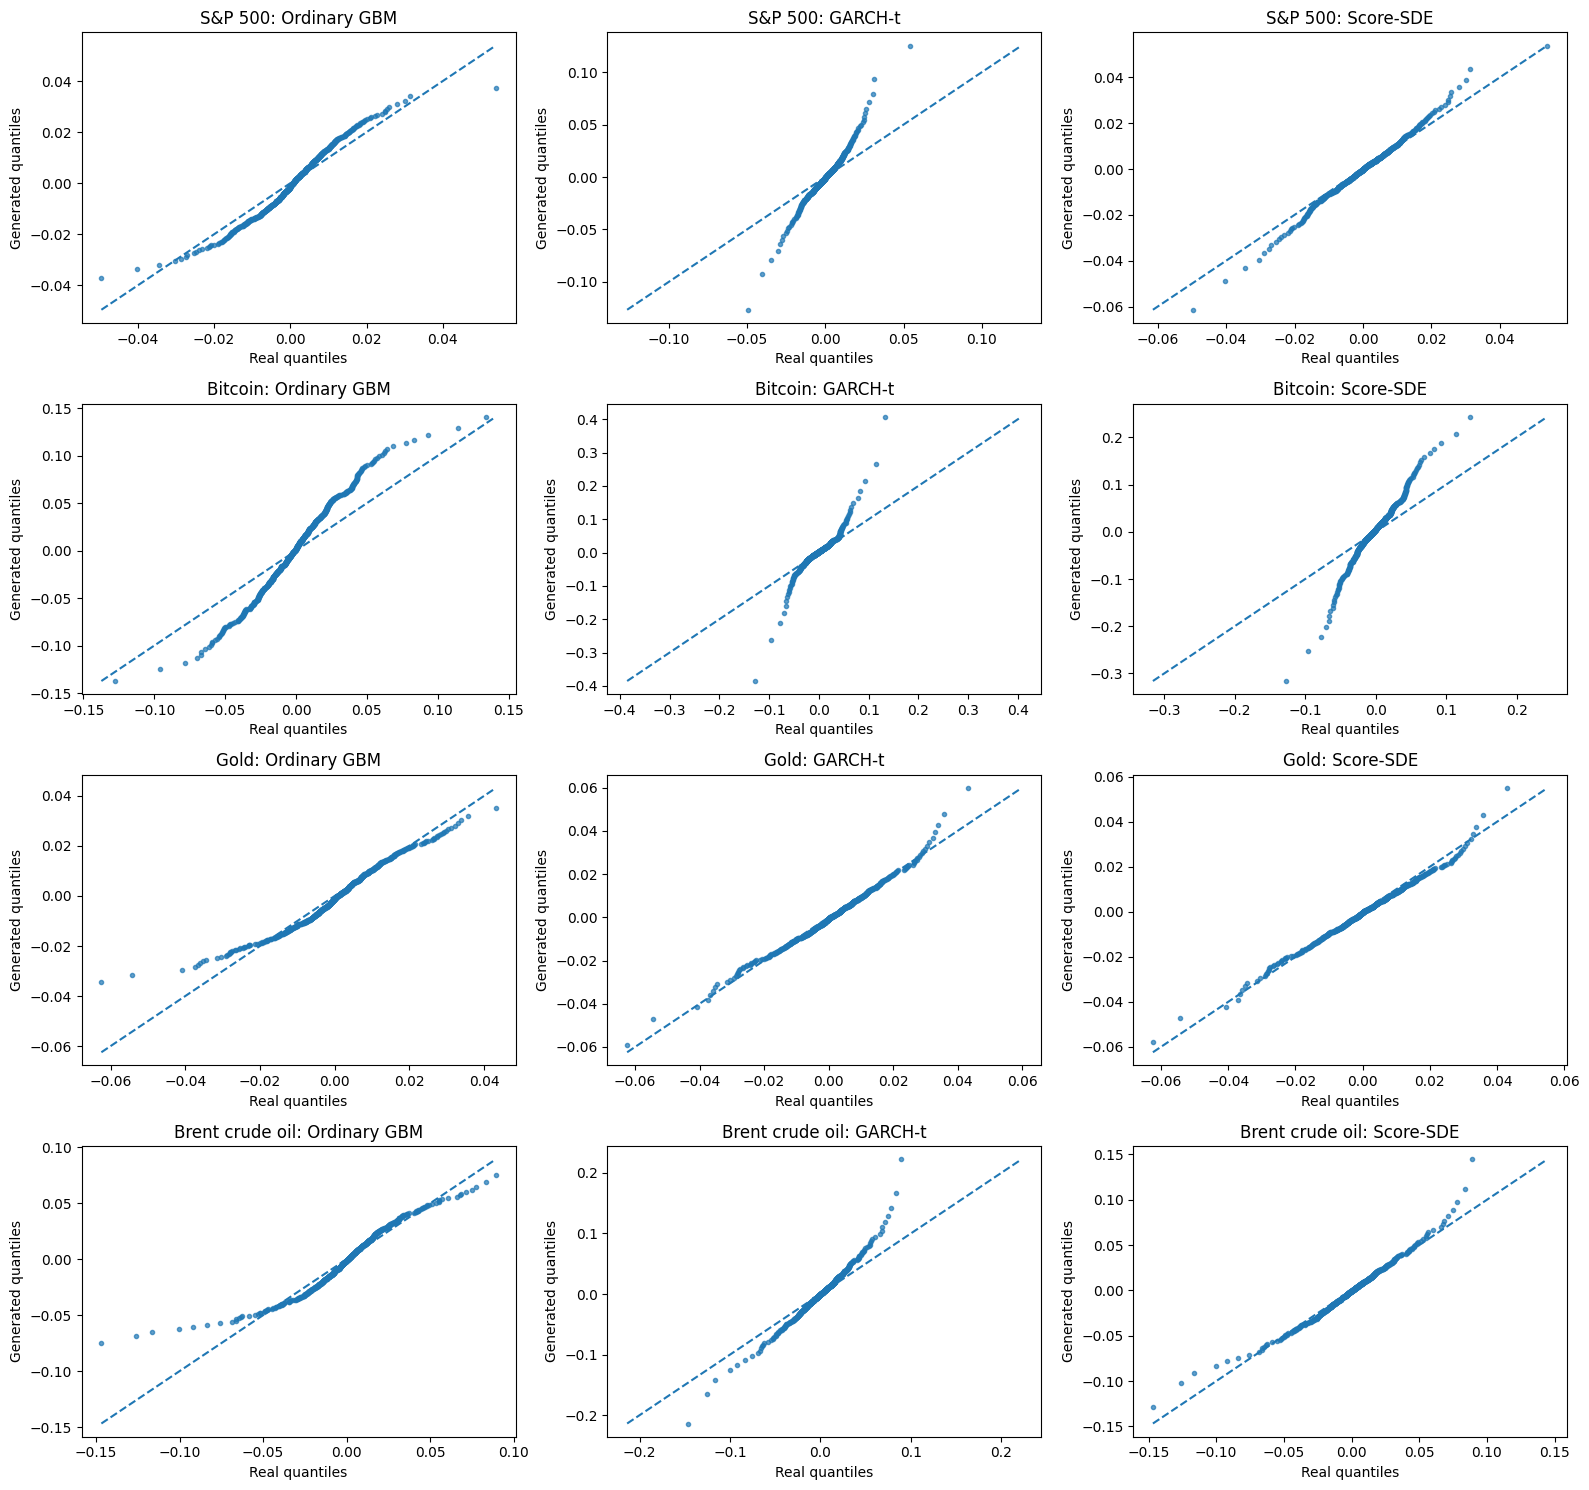

In [ ]:
fig, axes = plt.subplots(len(assets), 3, figsize=(16, 15))

probabilities = np.linspace(0.001, 0.999, 700)

for row, asset_name in enumerate(assets):
    real = prepared[asset_name]["real_test_returns"]

    for column, (model_name, generated) in enumerate([
        ("Ordinary GBM", gbm_generated_returns[asset_name].reshape(-1)),
        ("GARCH-t", garch_generated_returns[asset_name].reshape(-1)),
        ("Score-SDE", score_generated_returns[asset_name].reshape(-1)),
    ]):
        real_q = np.quantile(real, probabilities)
        generated_q = np.quantile(generated, probabilities)

        minimum = min(real_q.min(), generated_q.min())
        maximum = max(real_q.max(), generated_q.max())

        axes[row, column].scatter(real_q, generated_q, s=9, alpha=0.7)
        axes[row, column].plot([minimum, maximum], [minimum, maximum], linestyle="--")

        axes[row, column].set_title(f"{asset_name}: {model_name}")
        axes[row, column].set_xlabel("Real quantiles")
        axes[row, column].set_ylabel("Generated quantiles")

plt.tight_layout()
plt.savefig(results_dir / "08_qq_real_gbm_garch_score.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Q-Q Plot Observation

*The Q-Q plots show where the generated quantiles move away from the real quantiles. The S&P 500 Score-SDE stays comparatively close over a broad range, while Bitcoin departs much earlier in the tails. This full 12-panel figure is useful as an appendix figure because it compares all three generated models for every asset.*

## 15. Quantile Comparison

Here I compare selected lower-tail, central and upper-tail quantiles of the real and generated returns. The 1%, 2.5% and 5% quantiles are especially useful for checking downside risk, while the upper quantiles show whether positive extremes are also reproduced.

In [ ]:
quantile_levels = [0.01, 0.025, 0.05, 0.50, 0.95, 0.975, 0.99]
quantile_rows = []

for asset_name in assets:
    real = prepared[asset_name]["real_test_returns"]
    gbm = gbm_generated_returns[asset_name].reshape(-1)
    garch = garch_generated_returns[asset_name].reshape(-1)
    score = score_generated_returns[asset_name].reshape(-1)

    for probability in quantile_levels:
        quantile_rows.append({
            "Asset": asset_name,
            "Quantile": probability,
            "Real": np.quantile(real, probability),
            "Ordinary GBM": np.quantile(gbm, probability),
            "GARCH-t": np.quantile(garch, probability),
            "Score-SDE": np.quantile(score, probability),
        })

quantile_table = pd.DataFrame(quantile_rows)
display(quantile_table.round(6))
quantile_table.to_csv(results_dir / "09_quantile_comparison.csv", index=False)  # save the numerical results as csv

,Asset,Quantile,Real,Ordinary GBM,GARCH-t,Score-SDE
0,S&P 500,0.010,-0.026772,-0.027826,-0.055373,-0.032806
1,S&P 500,0.025,-0.018628,-0.023491,-0.038497,-0.024072
2,S&P 500,0.050,-0.015561,-0.019712,-0.027882,-0.018034
3,S&P 500,0.500,0.000812,0.000144,0.000638,0.000798
4,S&P 500,0.950,0.015342,0.019999,0.029191,0.017273
5,S&P 500,0.975,0.018739,0.023819,0.039708,0.022351
6,S&P 500,0.990,0.024806,0.028225,0.056606,0.029865
7,Bitcoin,0.010,-0.063359,-0.103238,-0.131387,-0.166365
8,Bitcoin,0.025,-0.052427,-0.086728,-0.082114,-0.118880
9,Bitcoin,0.050,-0.039970,-0.072426,-0.055257,-0.085789


### Quantile Result

*The downside quantiles confirm the same pattern. For the S&P 500 the Score-SDE 1% quantile is \(-0.0328\) compared with \(-0.0268\) in the real data. For Bitcoin it is much too negative at \(-0.1664\) compared with \(-0.0634\). Gold and Brent are much closer at the 1% level.*

## 16. Heavy-Tail Comparison

Here I compare survival curves of absolute returns. The curve shows how often returns larger than a given absolute size occur. Slower decay means more probability is placed in the tails and therefore more extreme returns are generated.

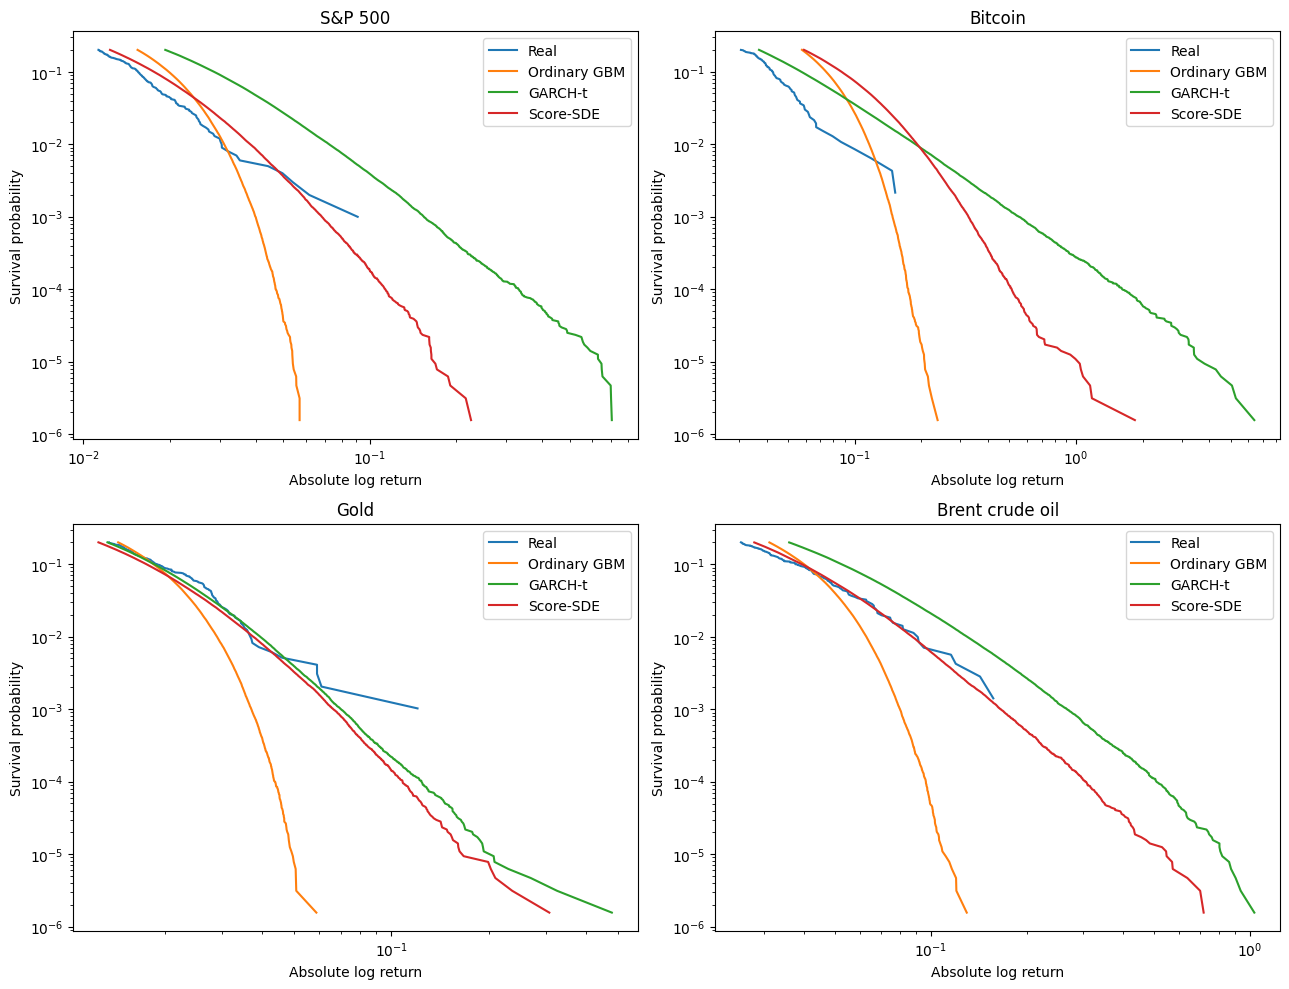

In [ ]:
def survival_curve(values):
    x = np.sort(np.abs(np.asarray(values)))
    x = x[x > 0]
    survival = 1.0 - np.arange(1, len(x) + 1) / (len(x) + 1)
    return x, survival

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    series = [
        (prepared[asset_name]["real_test_returns"], "Real"),
        (gbm_generated_returns[asset_name].reshape(-1), "Ordinary GBM"),
        (garch_generated_returns[asset_name].reshape(-1), "GARCH-t"),
        (score_generated_returns[asset_name].reshape(-1), "Score-SDE"),
    ]

    for values, label in series:
        x, y = survival_curve(values)
        start = int(0.80 * len(x))
        axis.loglog(x[start:], y[start:], label=label)

    axis.set_title(asset_name)
    axis.set_xlabel("Absolute log return")
    axis.set_ylabel("Survival probability")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "10_heavy_tail_survival.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Tail Plot Observation

*Ordinary GBM loses probability in the tails too quickly because its returns are Gaussian. The heavier-tailed models are closer for several assets, but Bitcoin shows that producing heavy tails is not enough: the generated tails can also become much too extreme.*

## 17. Core Financial Statistics and Risk Measures

Here I calculate the main distributional and risk measures used in the dissertation. These include mean, standard deviation, skewness, excess kurtosis, 1% VaR, 1% Expected Shortfall, the Hill tail index, the KS statistic and Wasserstein distance. KS and Wasserstein measure overall distributional fit, while the other statistics show where the differences come from.

In [ ]:
def expected_shortfall(values, probability=0.01):  # calculate the average return beyond the chosen var threshold
    values = np.asarray(values)
    threshold = np.quantile(values, probability)
    tail = values[values <= threshold]
    return float(tail.mean()) if len(tail) else np.nan

def hill_tail_index(values, fraction=0.05):  # estimate tail heaviness from the largest absolute returns
    values = np.abs(np.asarray(values))
    values = values[np.isfinite(values) & (values > 0)]
    values = np.sort(values)

    k = max(10, int(len(values) * fraction))
    tail = values[-k:]
    threshold = tail[0]
    denominator = np.mean(np.log(tail / threshold))

    return np.nan if denominator <= 0 else 1.0 / denominator

def distribution_metrics(real, generated):  # calculate the main distribution and risk measures
    return {
        "Mean": np.mean(generated),
        "Standard deviation": np.std(generated, ddof=1),
        "Skewness": stats.skew(generated, bias=False),
        "Excess kurtosis": stats.kurtosis(generated, fisher=True, bias=False),
        "1% VaR": np.quantile(generated, 0.01),
        "1% Expected shortfall": expected_shortfall(generated, 0.01),
        "Hill tail index": hill_tail_index(generated),
        "KS statistic": stats.ks_2samp(real, generated).statistic,  # ks measures the largest gap between the two empirical distributions
        "Wasserstein distance": wasserstein_distance(real, generated),  # wasserstein measures the overall distance between the distributions
    }

statistics_rows = []

for asset_name in assets:
    real = prepared[asset_name]["real_test_returns"]

    real_values = {
        "Mean": np.mean(real),
        "Standard deviation": np.std(real, ddof=1),
        "Skewness": stats.skew(real, bias=False),
        "Excess kurtosis": stats.kurtosis(real, fisher=True, bias=False),
        "1% VaR": np.quantile(real, 0.01),
        "1% Expected shortfall": expected_shortfall(real, 0.01),
        "Hill tail index": hill_tail_index(real),
        "KS statistic": 0.0,
        "Wasserstein distance": 0.0,
    }

    generated_sets = [
        ("Real", None),
        ("Ordinary GBM", gbm_generated_returns[asset_name].reshape(-1)),
        ("GARCH-t", garch_generated_returns[asset_name].reshape(-1)),
        ("Score-SDE", score_generated_returns[asset_name].reshape(-1)),
    ]

    for model_name, generated in generated_sets:
        values = real_values if model_name == "Real" else distribution_metrics(real, generated)

        row = {"Asset": asset_name, "Model": model_name}
        row.update(values)
        statistics_rows.append(row)

financial_statistics = pd.DataFrame(statistics_rows).set_index(["Asset", "Model"])
display(financial_statistics.round(6))
financial_statistics.to_csv(results_dir / "11_financial_statistics.csv")  # save the numerical results as csv

Mean  Standard deviation  Skewness  \
Asset           Model                                                  
S&P 500         Real          0.000596            0.010093  0.264906   
                Ordinary GBM  0.000145            0.012064  0.001198   
                GARCH-t       0.000623            0.020512 -0.004896   
                Score-SDE     0.000382            0.011466 -0.461437   
Bitcoin         Real         -0.000184            0.027378  0.112753   
                Ordinary GBM  0.001637            0.045059 -0.000960   
                GARCH-t       0.001888            0.058002  3.901154   
                Score-SDE     0.003101            0.055807 -0.736925   
Gold            Real          0.000872            0.012485 -1.246922   
                Ordinary GBM  0.000324            0.011230 -0.000635   
                GARCH-t       0.000430            0.012106  0.052611   
                Score-SDE     0.000349            0.011411 -0.149169   
Brent crude oil Real          0.000069            0.024836 -0.881664   
                Ordinary GBM -0.000124            0.024347 -0.001647   
                GARCH-t       0.000526            0.036816  0.078775   
                Score-SDE    -0.000088            0.026331 -0.013720   

                              Excess kurtosis    1% VaR  \
Asset           Model                                     
S&P 500         Real                 9.371554 -0.026772   
                Ordinary GBM         0.001654 -0.027826   
                GARCH-t             46.060645 -0.055373   
                Score-SDE            7.898170 -0.032806   
Bitcoin         Real                 4.281353 -0.063359   
                Ordinary GBM         0.003796 -0.103238   
                GARCH-t            925.557054 -0.131387   
                Score-SDE            9.756860 -0.166365   
Gold            Real                10.983858 -0.035022   
                Ordinary GBM         0.011465 -0.025862   
                GARCH-t             12.327107 -0.031977   
                Score-SDE            7.714497 -0.032636   
Brent crude oil Real                 5.954370 -0.073861   
                Ordinary GBM         0.003910 -0.056883   
                GARCH-t             23.074668 -0.101134   
                Score-SDE           13.726807 -0.070138   

                              1% Expected shortfall  Hill tail index  \
Asset           Model                                                  
S&P 500         Real                      -0.035936         2.991433   
                Ordinary GBM              -0.031967         6.020854   
                GARCH-t                   -0.085168         2.644837   
                Score-SDE                 -0.045001         3.232630   
Bitcoin         Real                      -0.091571         3.672967   
                Ordinary GBM              -0.118506         6.001537   
                GARCH-t                   -0.246639         2.008641   
                Score-SDE                 -0.229731         3.285714   
Gold            Real                      -0.050765         4.342269   
                Ordinary GBM              -0.029679         5.995472   
                GARCH-t                   -0.043717         3.311205   
                Score-SDE                 -0.043286         3.288543   
Brent crude oil Real                      -0.109609         2.968266   
                Ordinary GBM              -0.065064         6.016641   
                GARCH-t                   -0.149624         2.729760   
                Score-SDE                 -0.096400         3.108760   

                              KS statistic  Wasserstein distance  
Asset           Model                                             
S&P 500         Real              0.000000              0.000000  
                Ordinary GBM      0.112060              0.002802  
                GARCH-t           0.112032              0.005809  
                Score-SDE         0.029988

### Main Statistical Result

*The S&P 500 is the strongest Score-SDE case: its volatility and excess kurtosis are reasonably close to the real data. Bitcoin is the clearest failure because Score-SDE volatility is about \(0.0558\) compared with \(0.0274\) in the real test data, and its downside VaR and Expected Shortfall are much too severe. Gold and Brent give more mixed results.*

## 18. Autocorrelation and Volatility Clustering

Here I calculate autocorrelation for raw returns, absolute returns and squared returns. Raw-return autocorrelation checks linear dependence. Absolute- and squared-return autocorrelation are more useful for volatility clustering because persistent values indicate that high-volatility periods tend to be followed by other high-volatility periods.

*The real test windows overlap because the window stride is one, so the real-window ACF averages are descriptive diagnostics rather than independent replications.*

In [ ]:
def acf(values, maximum_lag):  # calculate sample autocorrelation up to the chosen lag
    values = np.asarray(values, dtype=np.float64)
    values = values - values.mean()
    denominator = np.dot(values, values)

    result = [1.0]

    for lag in range(1, maximum_lag + 1):
        if denominator == 0:
            result.append(np.nan)
        else:
            result.append(np.dot(values[:-lag], values[lag:]) / denominator)

    return np.asarray(result)

def average_window_acf(windows, maximum_lag, transform=None):  # average the acf calculated inside each path window
    curves = []

    for window in np.asarray(windows):
        values = window.copy()

        if transform is not None:
            values = transform(values)

        curve = acf(values, maximum_lag)

        if np.all(np.isfinite(curve)):
            curves.append(curve)

    return np.mean(np.asarray(curves), axis=0)

lags = np.arange(max_acf_lag + 1)

return_acf = {}
absolute_acf = {}
squared_acf = {}

for asset_name in assets:
    model_windows = {
        "Real": real_test_windows[asset_name],
        "Ordinary GBM": gbm_generated_returns[asset_name],
        "GARCH-t": garch_generated_returns[asset_name],
        "Score-SDE": score_generated_returns[asset_name],
    }

    for model_name, windows in model_windows.items():
        return_acf[(asset_name, model_name)] = average_window_acf(windows, max_acf_lag)
        absolute_acf[(asset_name, model_name)] = average_window_acf(windows, max_acf_lag, transform=np.abs)  # use absolute returns to measure volatility clustering
        squared_acf[(asset_name, model_name)] = average_window_acf(windows, max_acf_lag, transform=lambda x: x ** 2)  # use squared returns as a second volatility-clustering measure

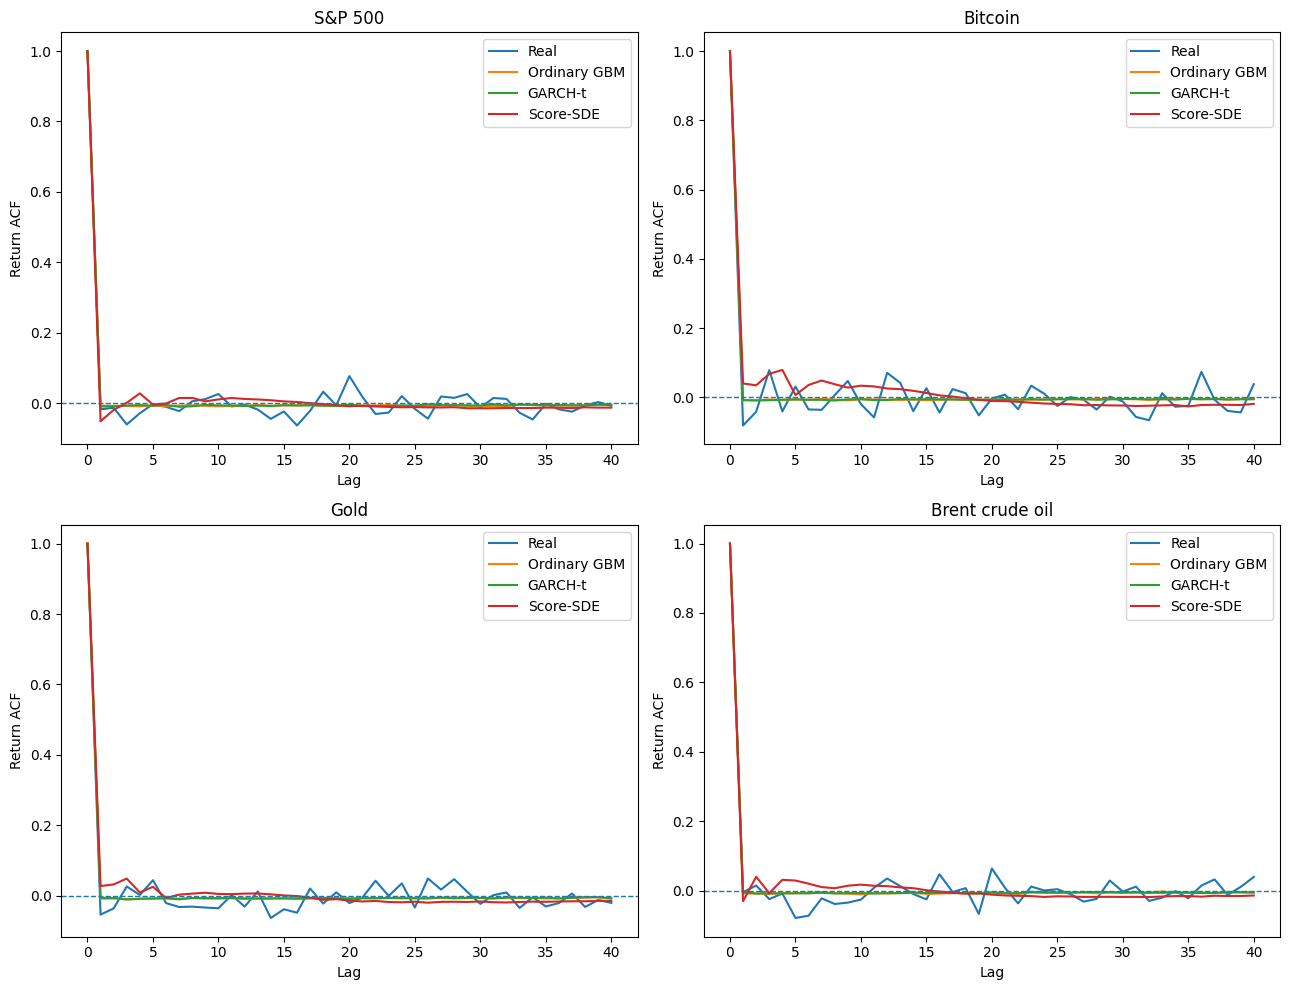

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    for model_name in ["Real", "Ordinary GBM", "GARCH-t", "Score-SDE"]:
        axis.plot(lags, return_acf[(asset_name, model_name)], label=model_name)

    axis.axhline(0, linestyle="--", linewidth=1)
    axis.set_title(asset_name)
    axis.set_xlabel("Lag")
    axis.set_ylabel("Return ACF")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "11_return_acf.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

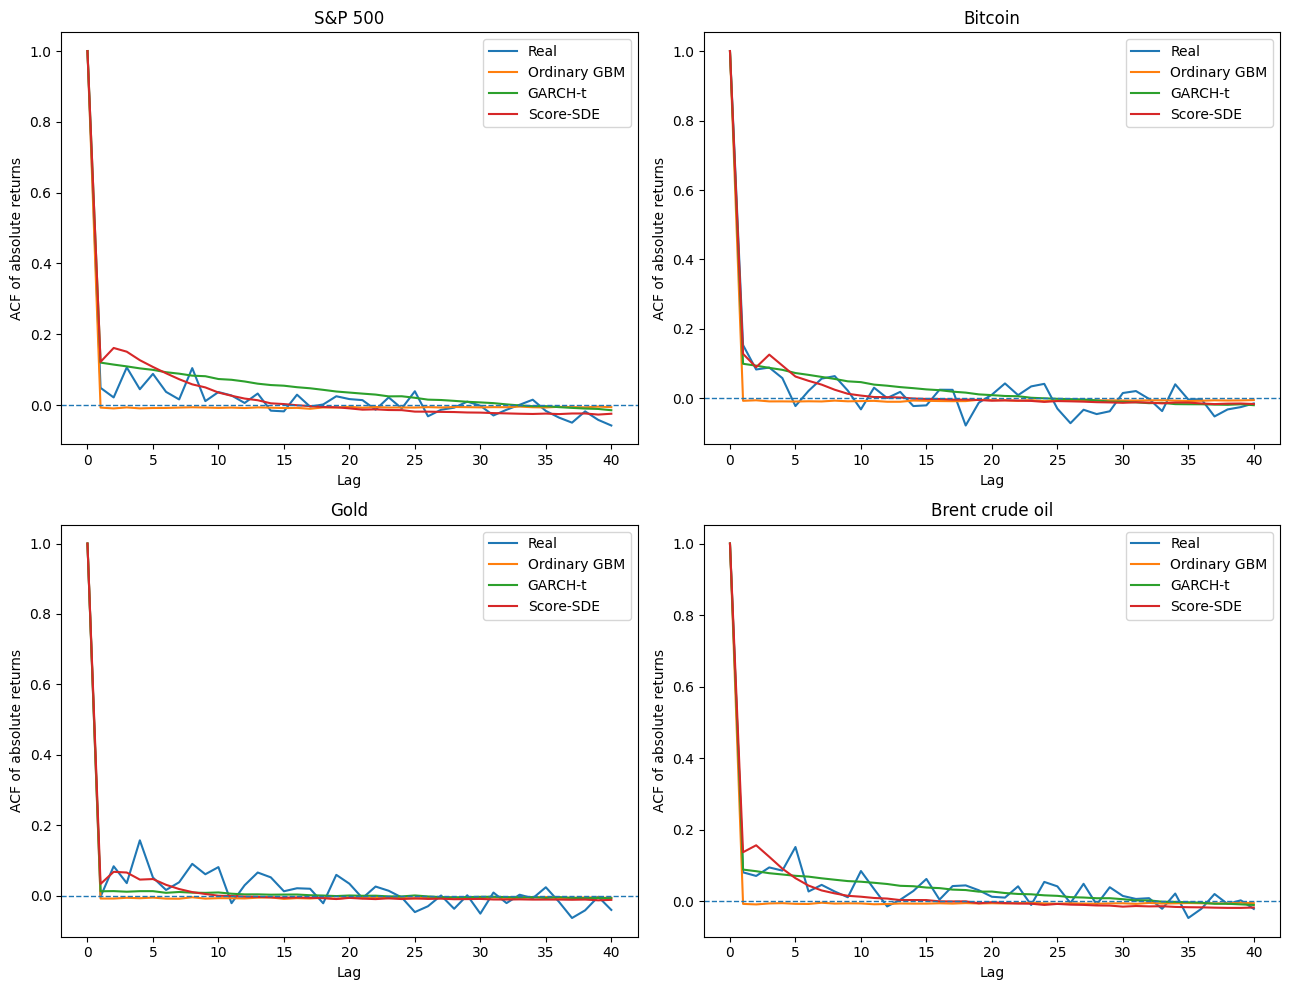

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    for model_name in ["Real", "Ordinary GBM", "GARCH-t", "Score-SDE"]:
        axis.plot(lags, absolute_acf[(asset_name, model_name)], label=model_name)

    axis.axhline(0, linestyle="--", linewidth=1)
    axis.set_title(asset_name)
    axis.set_xlabel("Lag")
    axis.set_ylabel("ACF of absolute returns")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "12_absolute_return_acf.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

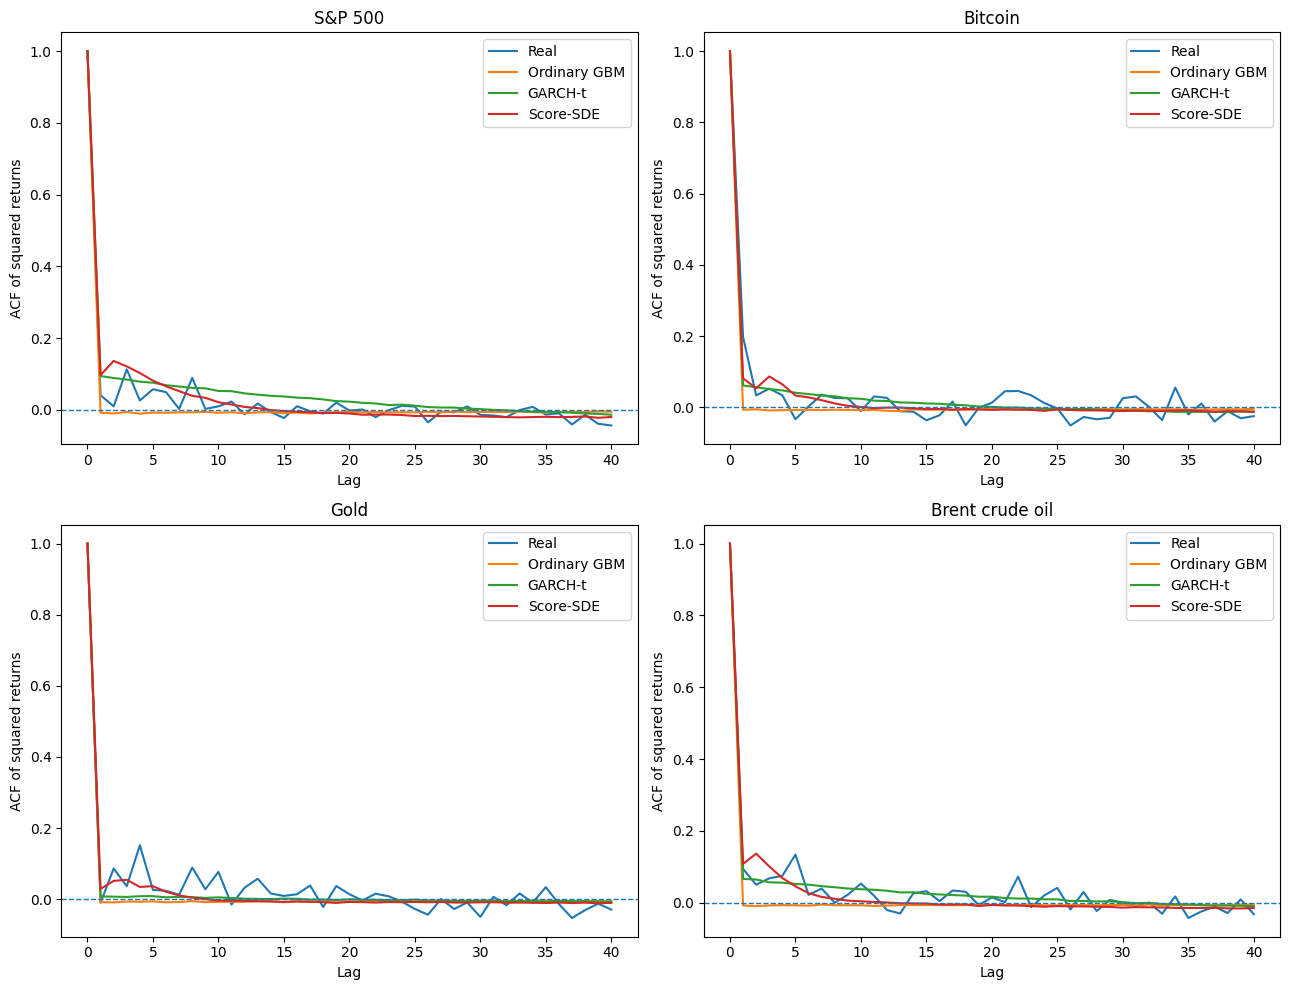

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    for model_name in ["Real", "Ordinary GBM", "GARCH-t", "Score-SDE"]:
        axis.plot(lags, squared_acf[(asset_name, model_name)], label=model_name)

    axis.axhline(0, linestyle="--", linewidth=1)
    axis.set_title(asset_name)
    axis.set_xlabel("Lag")
    axis.set_ylabel("ACF of squared returns")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "13_squared_return_acf.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Autocorrelation Observation

*The raw-return ACFs are generally small, while the absolute- and squared-return ACFs are more informative for volatility clustering. These plots should be read as descriptive comparisons because the real stride-one windows overlap and are not independent observations.*

## 19. Leverage-Type Dependence

Here I compare current returns with future squared returns over several lags. This is used as a leverage-type diagnostic: negative returns can be followed by higher future volatility in financial markets. The curves show whether the generated data reproduce a similar return-volatility relationship.

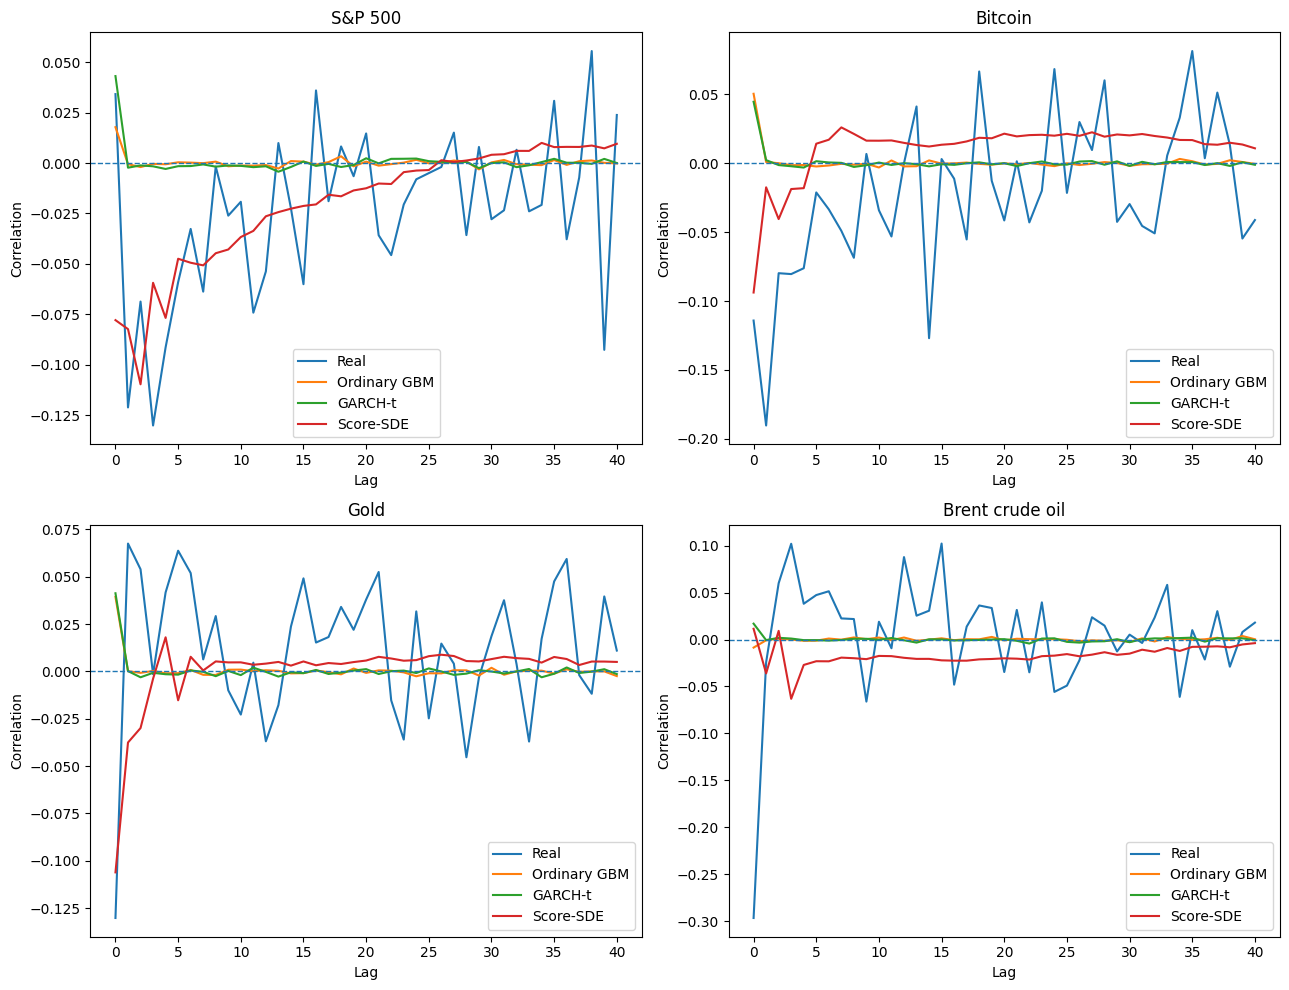

In [ ]:
def leverage_curve(windows, maximum_lag):  # measure the relation between current returns and future squared returns
    curves = []

    for window in np.asarray(windows):
        row = []

        for lag in range(maximum_lag + 1):
            if lag == 0:
                current = window
                future_squared = window ** 2  # use future squared returns as a volatility proxy
            else:
                current = window[:-lag]
                future_squared = window[lag:] ** 2  # use future squared returns as a volatility proxy

            if np.std(current) == 0 or np.std(future_squared) == 0:
                row.append(np.nan)
            else:
                row.append(np.corrcoef(current, future_squared)[0, 1])

        curves.append(row)

    return np.nanmean(np.asarray(curves), axis=0)

leverage_lags = np.arange(max_leverage_lag + 1)
leverage_results = {}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    model_windows = {
        "Real": real_test_windows[asset_name],
        "Ordinary GBM": gbm_generated_returns[asset_name],
        "GARCH-t": garch_generated_returns[asset_name],
        "Score-SDE": score_generated_returns[asset_name],
    }

    for model_name, windows in model_windows.items():
        curve = leverage_curve(windows, max_leverage_lag)
        leverage_results[(asset_name, model_name)] = curve
        axis.plot(leverage_lags, curve, label=model_name)

    axis.axhline(0, linestyle="--", linewidth=1)
    axis.set_title(asset_name)
    axis.set_xlabel("Lag")
    axis.set_ylabel("Correlation")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "14_leverage_effect.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Leverage Observation

*The leverage curves are another temporal diagnostic rather than a stand-alone model ranking. The important question is whether the generated return-volatility relationship follows a similar shape and scale to the real data across the lags.*

## 20. Twenty-Day Rolling Volatility

Here I calculate rolling volatility over 20 trading days. This gives a direct view of how the local volatility level changes through a path and whether the generated series contain realistic calm and high-volatility periods.

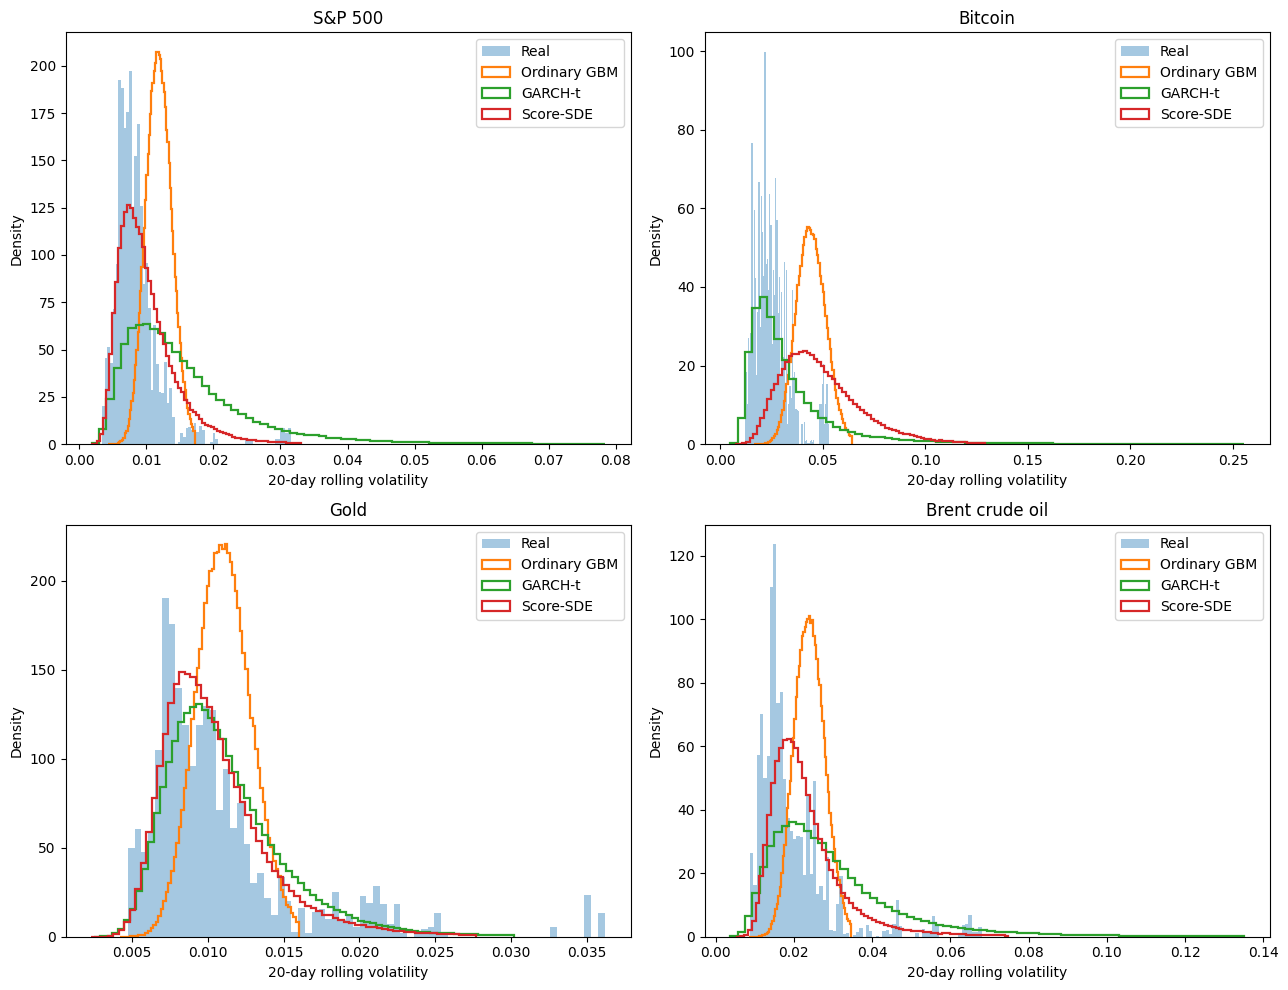

In [ ]:
def rolling_volatility_from_windows(windows, rolling_window=20):  # calculate rolling volatility inside each path
    values = []

    for window in np.asarray(windows):
        series = pd.Series(window)
        rolling = series.rolling(rolling_window).std(ddof=1).dropna().values  # calculate the local standard deviation over 20 days
        values.extend(rolling)

    return np.asarray(values)

rolling_volatility = {}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for axis, asset_name in zip(axes, assets):
    model_windows = {
        "Real": real_test_windows[asset_name],
        "Ordinary GBM": gbm_generated_returns[asset_name],
        "GARCH-t": garch_generated_returns[asset_name],
        "Score-SDE": score_generated_returns[asset_name],
    }

    for model_name, windows in model_windows.items():
        values = rolling_volatility_from_windows(windows, rolling_volatility_window)
        rolling_volatility[(asset_name, model_name)] = values

        upper = np.quantile(values, 0.995)
        axis.hist(
            values[values <= upper],
            bins=70,
            density=True,
            histtype="step" if model_name != "Real" else "bar",
            alpha=0.40 if model_name == "Real" else 1.0,
            linewidth=1.6,
            label=model_name,
        )

    axis.set_title(asset_name)
    axis.set_xlabel("20-day rolling volatility")
    axis.set_ylabel("Density")
    axis.legend()

plt.tight_layout()
plt.savefig(results_dir / "15_rolling_volatility.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

In [ ]:
rolling_rows = []

for asset_name in assets:
    for model_name in ["Real", "Ordinary GBM", "GARCH-t", "Score-SDE"]:
        values = rolling_volatility[(asset_name, model_name)]

        rolling_rows.append({
            "Asset": asset_name,
            "Model": model_name,
            "Mean rolling volatility": np.mean(values),
            "Median rolling volatility": np.median(values),
            "95% rolling volatility": np.quantile(values, 0.95),
            "99% rolling volatility": np.quantile(values, 0.99),
        })

rolling_table = pd.DataFrame(rolling_rows).set_index(["Asset", "Model"])
display(rolling_table.round(6))
rolling_table.to_csv(results_dir / "16_rolling_volatility_summary.csv")  # save the numerical results as csv

Mean rolling volatility  \
Asset           Model                                   
S&P 500         Real                         0.008834   
                Ordinary GBM                 0.011908   
                GARCH-t                      0.016332   
                Score-SDE                    0.010249   
Bitcoin         Real                         0.025519   
                Ordinary GBM                 0.044462   
                GARCH-t                      0.037232   
                Score-SDE                    0.049832   
Gold            Real                         0.011038   
                Ordinary GBM                 0.011080   
                GARCH-t                      0.011258   
                Score-SDE                    0.010589   
Brent crude oil Real                         0.019960   
                Ordinary GBM                 0.024027   
                GARCH-t                      0.030681   
                Score-SDE                    0.023447   

                              Median rolling volatility  \
Asset           Model                                     
S&P 500         Real                           0.007904   
                Ordinary GBM                   0.011859   
                GARCH-t                        0.013336   
                Score-SDE                      0.009145   
Bitcoin         Real                           0.024072   
                Ordinary GBM                   0.044239   
                GARCH-t                        0.027227   
                Score-SDE                      0.046051   
Gold            Real                           0.009529   
                Ordinary GBM                   0.011026   
                GARCH-t                        0.010391   
                Score-SDE                      0.009798   
Brent crude oil Real                           0.016495   
                Ordinary GBM                   0.023925   
                GARCH-t                        0.025779   
                Score-SDE                      0.021001   

                              95% rolling volatility  99% rolling volatility  
Asset           Model                                                         
S&P 500         Real                        0.015965                0.030758  
                Ordinary GBM                0.015164                0.016634  
                GARCH-t                     0.036259                0.063246  
                Score-SDE                   0.018994                0.027965  
Bitcoin         Real                        0.049451                0.052207  
                Ordinary GBM                0.056701                0.062217  
                GARCH-t                     0.087786                0.187724  
                Score-SDE                   0.088520                0.116801  
Gold            Real                        0.021525                0.035963  
                Ordinary GBM                0.014179                0.015519  
                GARCH-t                     0.018929                0.026260  
                Score-SDE                   0.017568                0.024187  
Brent crude oil Real                        0.045720                0.065380  
                Ordinary GBM                0.030715                0.033608  
                GARCH-t                     0.065476                0.107464  
                Score-SDE                   0.042284                0.064412

### Rolling-Volatility Result

*Score-SDE is close to the real S&P 500 and Brent upper rolling-volatility levels. For example, the S&P 500 99% rolling volatility is about \(0.0280\) for Score-SDE versus \(0.0308\) in the real data, and Brent is \(0.0644\) versus \(0.0654\). Bitcoin is again much too volatile: \(0.1168\) versus \(0.0522\).*

## 21. Multi-Horizon Returns

Here I aggregate log returns over 1-, 5- and 20-day horizons. I then compare volatility, excess kurtosis, Wasserstein distance, VaR and Expected Shortfall at each horizon. This checks whether a model that performs well for daily returns continues to behave reasonably when returns are accumulated over longer periods.

In [ ]:
def aggregate_series(values, horizon):  # sum consecutive log returns over the selected horizon
    values = np.asarray(values, dtype=np.float64).reshape(-1)

    if horizon == 1:
        return values.copy()

    return np.convolve(values, np.ones(horizon), mode="valid")  # rolling sum of log returns

def aggregate_windows(windows, horizon):  # aggregate each generated path at the same horizon
    aggregated = []

    for window in np.asarray(windows):
        aggregated.extend(aggregate_series(window, horizon))

    return np.asarray(aggregated)

multi_horizon_rows = []

for asset_name in assets:
    real_raw = prepared[asset_name]["real_test_returns"]

    for horizon in horizons:
        real_h = aggregate_series(real_raw, horizon)
        gbm_h = aggregate_windows(gbm_generated_returns[asset_name], horizon)
        score_h = aggregate_windows(score_generated_returns[asset_name], horizon)

        for model_name, generated_h in [
            ("Ordinary GBM", gbm_h),
            ("Score-SDE", score_h),
        ]:
            multi_horizon_rows.append({
                "Asset": asset_name,
                "Horizon": horizon,
                "Model": model_name,
                "Real volatility": np.std(real_h, ddof=1),
                "Generated volatility": np.std(generated_h, ddof=1),
                "Real excess kurtosis": stats.kurtosis(real_h, fisher=True, bias=False),
                "Generated excess kurtosis": stats.kurtosis(generated_h, fisher=True, bias=False),
                "Wasserstein distance": wasserstein_distance(real_h, generated_h),
                "Real 1% VaR": np.quantile(real_h, 0.01),
                "Generated 1% VaR": np.quantile(generated_h, 0.01),
                "Real 1% Expected shortfall": expected_shortfall(real_h, 0.01),
                "Generated 1% Expected shortfall": expected_shortfall(generated_h, 0.01),
            })

multi_horizon_table = pd.DataFrame(multi_horizon_rows).set_index(["Asset", "Horizon", "Model"])
display(multi_horizon_table.round(6))
multi_horizon_table.to_csv(results_dir / "17_multi_horizon_analysis.csv")  # save the numerical results as csv

Real volatility  Generated volatility  \
Asset           Horizon Model                                                 
S&P 500         1       Ordinary GBM         0.010093              0.012064   
                        Score-SDE            0.010093              0.011466   
                5       Ordinary GBM         0.021032              0.027002   
                        Score-SDE            0.021032              0.024598   
                20      Ordinary GBM         0.039682              0.054140   
                        Score-SDE            0.039682              0.054327   
Bitcoin         1       Ordinary GBM         0.027378              0.045059   
                        Score-SDE            0.027378              0.055807   
                5       Ordinary GBM         0.059323              0.100824   
                        Score-SDE            0.059323              0.137721   
                20      Ordinary GBM         0.128355              0.202516   
                        Score-SDE            0.128355              0.334609   
Gold            1       Ordinary GBM         0.012485              0.011230   
                        Score-SDE            0.012485              0.011411   
                5       Ordinary GBM         0.026220              0.025081   
                        Score-SDE            0.026220              0.027476   
                20      Ordinary GBM         0.047669              0.050129   
                        Score-SDE            0.047669              0.060544   
Brent crude oil 1       Ordinary GBM         0.024836              0.024347   
                        Score-SDE            0.024836              0.026331   
                5       Ordinary GBM         0.053196              0.054373   
                        Score-SDE            0.053196              0.060892   
                20      Ordinary GBM         0.103331              0.108580   
                        Score-SDE            0.103331              0.139052   

                                      Real excess kurtosis  \
Asset           Horizon Model                                
S&P 500         1       Ordinary GBM              9.371558   
                        Score-SDE                 9.371558   
                5       Ordinary GBM              2.441481   
                        Score-SDE                 2.441481   
                20      Ordinary GBM              0.767086   
                        Score-SDE                 0.767086   
Bitcoin         1       Ordinary GBM              4.281353   
                        Score-SDE                 4.281353   
                5       Ordinary GBM              2.779389   
                        Score-SDE                 2.779389   
                20      Ordinary GBM              0.714827   
                        Score-SDE                 0.714827   
Gold            1       Ordinary GBM             10.983859   
                        Score-SDE                10.983859   
                5       Ordinary GBM              2.524820   
                        Score-SDE                 2.524820   
                20      Ordinary GBM              1.123720   
                        Score-SDE                 1.123720   
Brent crude oil 1       Ordinary GBM              5.954370   
                        Score-SDE                 5.954370   
                5       Ordinary GBM              2.532466   
                        Score-SDE                 2.532466   
                20      Ordinary GBM              4.585179   
                        Score-SDE                 4.585179   

                                      Generated excess kurtosis  \
Asset           Horizon Model                                     
S&P 500         1       Ordinary GBM                   0.001654   
                        Score-SDE                      7.898178   
                5       Ordinary GBM                   0.008133   
                        Score-SDE  

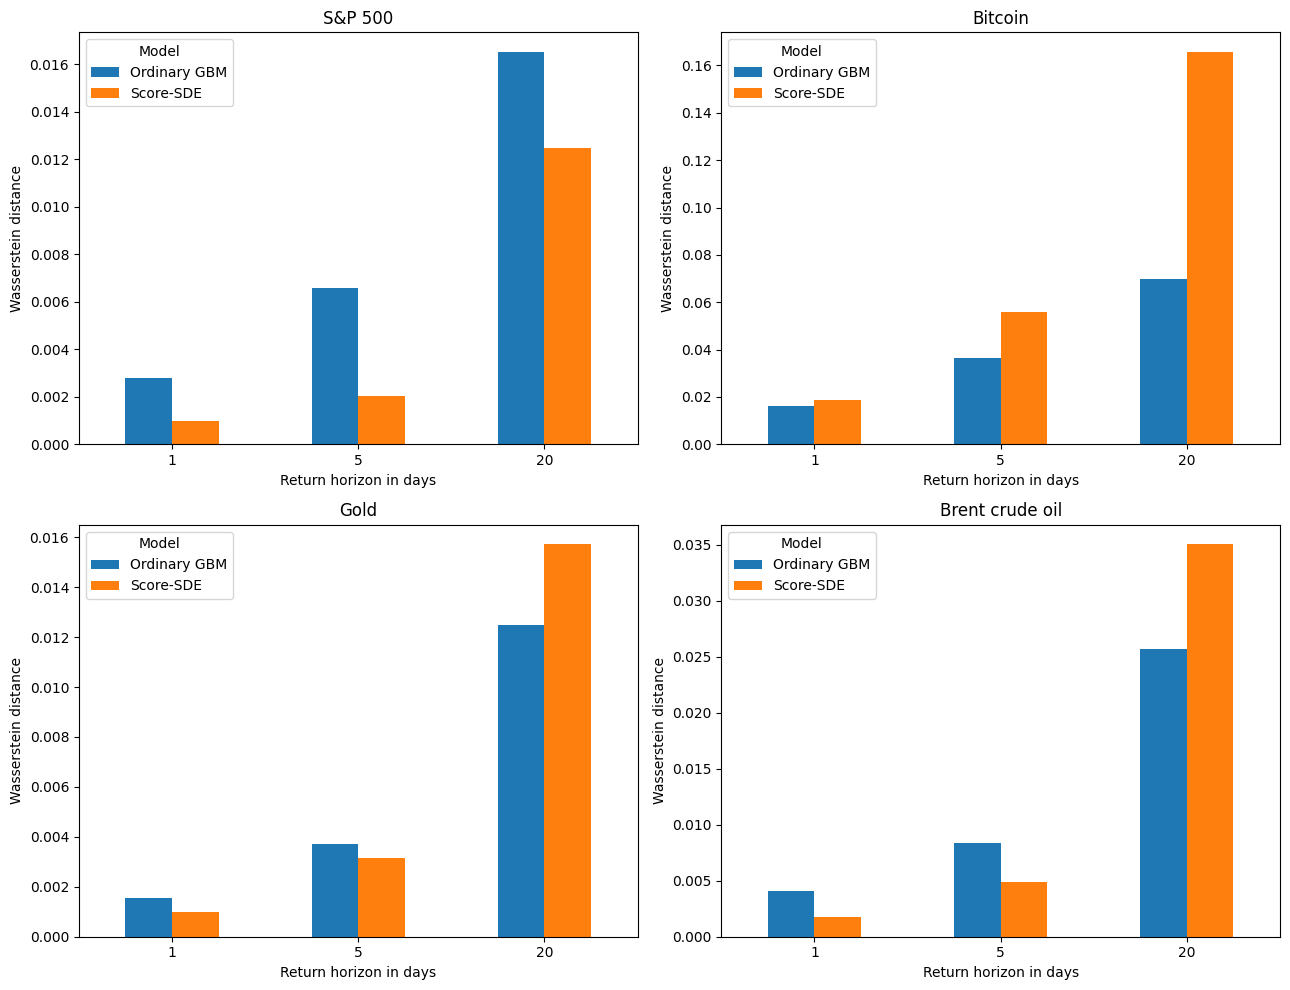

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

plot_data = multi_horizon_table.reset_index()

for axis, asset_name in zip(axes, assets):
    subset = plot_data[plot_data["Asset"] == asset_name]
    pivot = subset.pivot(index="Horizon", columns="Model", values="Wasserstein distance")
    pivot.plot(kind="bar", ax=axis)

    axis.set_title(asset_name)
    axis.set_xlabel("Return horizon in days")
    axis.set_ylabel("Wasserstein distance")
    axis.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(results_dir / "18_multi_horizon_wasserstein.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Multi-Horizon Observation

*The errors do not disappear when returns are aggregated. Bitcoin becomes especially problematic as the horizon increases, while the S&P 500 and Gold remain more stable. This shows why daily distribution fit alone is not enough for a financial generator.*

## 22. Bitcoin Failure Diagnosis

Bitcoin is the clearest failure case for the final Score-SDE, so I examine it separately rather than hiding the poor result. Here I check whether the problem is caused by only a few extreme simulations or whether excessive volatility is present across typical generated paths.

In [ ]:
asset_name = "Bitcoin"

real_windows = real_test_windows[asset_name]
score_windows = score_generated_returns[asset_name]

real_path_volatility = np.std(real_windows, axis=1, ddof=1)  # volatility of each real test window
score_path_volatility = np.std(score_windows, axis=1, ddof=1)  # volatility of each generated path

real_max_absolute = np.max(np.abs(real_windows), axis=1)  # largest return inside each real window
score_max_absolute = np.max(np.abs(score_windows), axis=1)  # largest return inside each generated path

real_extreme_threshold = np.quantile(np.abs(prepared[asset_name]["real_test_returns"]), 0.999)  # extreme real-return threshold
generated_extreme_share = np.mean(np.max(np.abs(score_windows), axis=1) > real_extreme_threshold)  # share of synthetic paths crossing it

bitcoin_diagnosis = pd.DataFrame({
    "Measure": [
        "Median real path volatility",
        "Median Score-SDE path volatility",
        "95% real path volatility",
        "95% Score-SDE path volatility",
        "Median real maximum absolute return",
        "Median Score-SDE maximum absolute return",
        "Real-test 99.9% absolute-return threshold",
        "Share of Score-SDE paths exceeding that threshold",
    ],
    "Value": [
        np.median(real_path_volatility),
        np.median(score_path_volatility),
        np.quantile(real_path_volatility, 0.95),
        np.quantile(score_path_volatility, 0.95),
        np.median(real_max_absolute),
        np.median(score_max_absolute),
        real_extreme_threshold,
        generated_extreme_share,
    ],
})

display(bitcoin_diagnosis.round(6))
bitcoin_diagnosis.to_csv(results_dir / "19_bitcoin_failure_diagnosis.csv", index=False)  # save the numerical results as csv

,Measure,Value
0,Median real path volatility,0.027823
1,Median Score-SDE path volatility,0.053010
2,95% real path volatility,0.031552
3,95% Score-SDE path volatility,0.075990
4,Median real maximum absolute return,0.099440
5,Median Score-SDE maximum absolute return,0.212383
6,Real-test 99.9% absolute-return threshold,0.150041
7,Share of Score-SDE paths exceeding that threshold,0.886600


### Bitcoin Failure Result

*The Bitcoin problem is systematic rather than being caused by only a few unusual simulations. Median Score-SDE path volatility is \(0.0530\) compared with \(0.0278\) for the real windows, and 88.66% of generated paths contain at least one absolute return above the real test 99.9% threshold.*

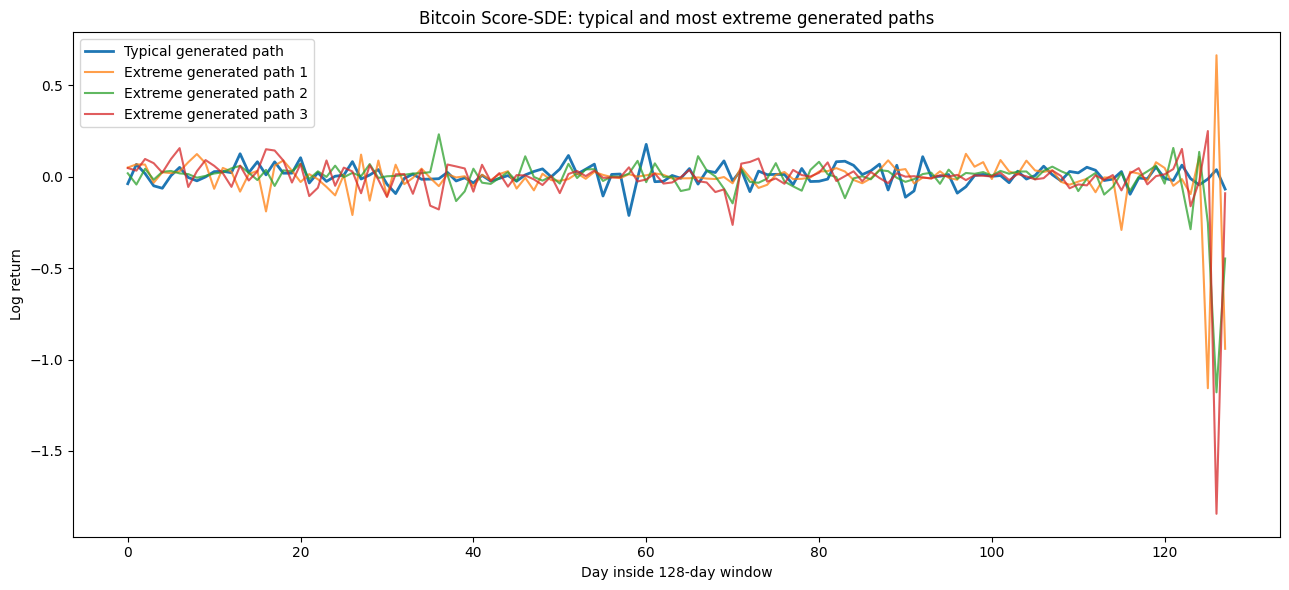

In [ ]:
path_order = np.argsort(score_max_absolute)
typical_index = path_order[len(path_order) // 2]  # path near the median maximum return
extreme_indices = path_order[-3:]  # three most extreme generated paths

plt.figure(figsize=(13, 6))
plt.plot(score_windows[typical_index], linewidth=2, label="Typical generated path")

for position, index in enumerate(extreme_indices):
    plt.plot(score_windows[index], alpha=0.75, label=f"Extreme generated path {position + 1}")

plt.title("Bitcoin Score-SDE: typical and most extreme generated paths")
plt.xlabel("Day inside 128-day window")
plt.ylabel("Log return")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "20_bitcoin_extreme_paths.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Bitcoin Path Plot Observation

*The typical generated path already contains larger movements than the real data would suggest, while the most extreme generated paths contain very large jumps. This supports the conclusion that the Bitcoin distribution is over-dispersed rather than suffering from only one isolated numerical failure.*

## 23. Diffusion Representation Comparison

Here I compare the return-space VE-SDE with the final relative log-price Score-SDE. The purpose is to test whether changing the representation itself improves the diffusion model. Lower KS, Wasserstein, kurtosis error and ACF errors indicate a closer match to the real test data.

In [ ]:
diffusion_rows = []  # collect the return-space and relative-log-price comparison

for asset_name in assets:
    real = prepared[asset_name]["real_test_returns"]
    baseline = return_ve_generated[asset_name].reshape(-1)
    score = score_generated_returns[asset_name].reshape(-1)

    real_abs = average_window_acf(real_test_windows[asset_name], max_acf_lag, transform=np.abs)  # use absolute returns to measure volatility clustering
    real_sq = average_window_acf(real_test_windows[asset_name], max_acf_lag, transform=lambda x: x ** 2)  # use squared returns as a second volatility-clustering measure

    for model_name, generated, windows in [
        ("Return-space VE-SDE", baseline, return_ve_generated[asset_name]),
        ("Relative log-price Score-SDE", score, score_generated_returns[asset_name]),
    ]:
        generated_abs = average_window_acf(windows, max_acf_lag, transform=np.abs)  # use absolute returns to measure volatility clustering
        generated_sq = average_window_acf(windows, max_acf_lag, transform=lambda x: x ** 2)  # use squared returns as a second volatility-clustering measure

        diffusion_rows.append({
            "Asset": asset_name,
            "Model": model_name,
            "KS statistic": stats.ks_2samp(real, generated).statistic,  # ks measures the largest gap between the two empirical distributions
            "Wasserstein distance": wasserstein_distance(real, generated),  # wasserstein measures the overall distance between the distributions
            "Absolute kurtosis error": abs(
                stats.kurtosis(real, fisher=True, bias=False)
                - stats.kurtosis(generated, fisher=True, bias=False)
            ),
            "Absolute-return ACF MAE": np.nanmean(np.abs(real_abs[1:] - generated_abs[1:])),
            "Squared-return ACF MAE": np.nanmean(np.abs(real_sq[1:] - generated_sq[1:])),
        })

diffusion_comparison = pd.DataFrame(diffusion_rows).set_index(["Asset", "Model"])
display(diffusion_comparison.round(6))
diffusion_comparison.to_csv(results_dir / "21_diffusion_method_comparison.csv")  # save the numerical results as csv

KS statistic  \
Asset           Model                                        
S&P 500         Return-space VE-SDE               0.077163   
                Relative log-price Score-SDE      0.029988   
Bitcoin         Return-space VE-SDE               0.080372   
                Relative log-price Score-SDE      0.161280   
Gold            Return-space VE-SDE               0.052293   
                Relative log-price Score-SDE      0.046025   
Brent crude oil Return-space VE-SDE               0.022899   
                Relative log-price Score-SDE      0.036444   

                                              Wasserstein distance  \
Asset           Model                                                
S&P 500         Return-space VE-SDE                       0.002446   
                Relative log-price Score-SDE              0.000969   
Bitcoin         Return-space VE-SDE                       0.008986   
                Relative log-price Score-SDE              0.018553   
Gold            Return-space VE-SDE                       0.001327   
                Relative log-price Score-SDE              0.000993   
Brent crude oil Return-space VE-SDE                       0.001159   
                Relative log-price Score-SDE              0.001790   

                                              Absolute kurtosis error  \
Asset           Model                                                   
S&P 500         Return-space VE-SDE                          5.225596   
                Relative log-price Score-SDE                 1.473384   
Bitcoin         Return-space VE-SDE                          3.060127   
                Relative log-price Score-SDE                 5.475507   
Gold            Return-space VE-SDE                          6.819175   
                Relative log-price Score-SDE                 3.269362   
Brent crude oil Return-space VE-SDE                          1.921472   
                Relative log-price Score-SDE                 7.772436   

                                              Absolute-return ACF MAE  \
Asset           Model                                                   
S&P 500         Return-space VE-SDE                          0.049731   
                Relative log-price Score-SDE                 0.027796   
Bitcoin         Return-space VE-SDE                          0.027940   
                Relative log-price Score-SDE                 0.028033   
Gold            Return-space VE-SDE                          0.029108   
                Relative log-price Score-SDE                 0.031062   
Brent crude oil Return-space VE-SDE                          0.036196   
                Relative log-price Score-SDE                 0.029421   

                                              Squared-return ACF MAE  
Asset           Model                                                 
S&P 500         Return-space VE-SDE                         0.037882  
                Relative log-price Score-SDE                0.021688  
Bitcoin         Return-space VE-SDE                         0.027277  
                Relative log-price Score-SDE                0.028142  
Gold            Return-space VE-SDE                         0.025520  
                Relative log-price Score-SDE                0.026654  
Brent crude oil Return-space VE-SDE                         0.026740  
                Relative log-price Score-SDE                0.025024

### Representation Result

*The relative log-price representation helps strongly for the S&P 500: KS falls from about \(0.0772\) to \(0.0300\), and Wasserstein distance falls from \(0.00245\) to \(0.00097\). It also improves several Gold distribution measures. However, it is worse for Bitcoin and for Brent on the main marginal-distribution measures. The representation is therefore not universally better.*

## 24. Reverse-Sampling Sensitivity

Here I keep the trained S&P 500 Score-SDE fixed and change only the number of reverse-sampling steps. I compare 100, 250, 500 and 1,000 steps to see whether a finer numerical discretisation gives a better distributional fit and how much extra runtime it requires.

In [ ]:
sensitivity_rows = []

real_sp = prepared["S&P 500"]["real_test_returns"]

for step_count in sensitivity_steps:
    start_time = time.perf_counter()  # start timing this reverse-sampling run

    generated_scaled = reverse_sample_batched(
        final_score_models["S&P 500"],
        window_length + 1,
        sensitivity_paths,
        step_count,
        generation_batch_size,
        seed + 7000 + step_count,
    )

    elapsed = time.perf_counter() - start_time  # record the sampling runtime

    generated_paths = generated_scaled * prepared["S&P 500"]["path_scale"]
    generated_paths = generated_paths - generated_paths[:, :1]
    generated_returns = np.diff(generated_paths, axis=1).reshape(-1)  # convert generated relative log prices back to returns

    sensitivity_rows.append({
        "Reverse steps": step_count,
        "Paths": sensitivity_paths,
        "KS statistic": stats.ks_2samp(real_sp, generated_returns).statistic,
        "Wasserstein distance": wasserstein_distance(real_sp, generated_returns),
        "Runtime seconds": elapsed,
    })

sampling_sensitivity = pd.DataFrame(sensitivity_rows).set_index("Reverse steps")
display(sampling_sensitivity.round(6))
sampling_sensitivity.to_csv(results_dir / "22_reverse_sampling_sensitivity.csv")  # save the numerical results as csv

generated 500 of 500
generated 500 of 500
generated 500 of 500
generated 500 of 500


,Paths,KS statistic,Wasserstein distance,Runtime seconds
Reverse steps,,,,
100,500,0.034782,0.001066,0.953013
250,500,0.026352,0.000853,2.225834
500,500,0.032524,0.001006,4.476803
1000,500,0.030367,0.000857,9.021331


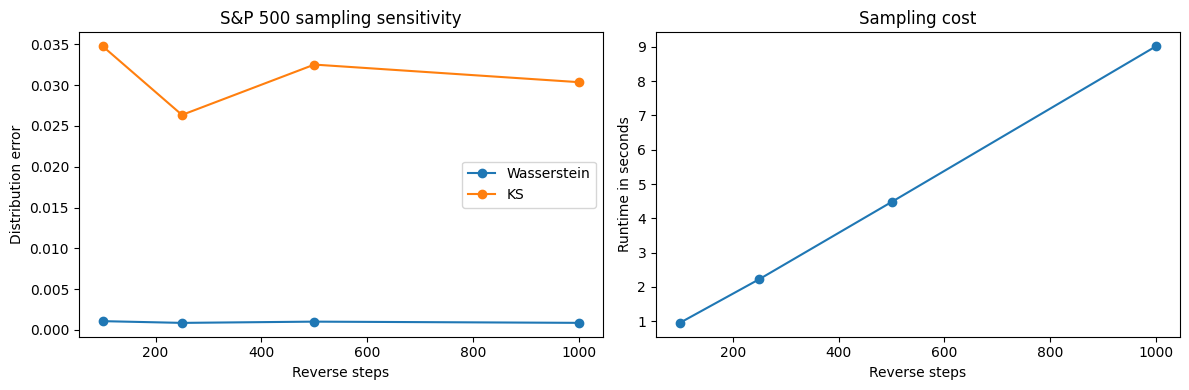

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    sampling_sensitivity.index,
    sampling_sensitivity["Wasserstein distance"],
    marker="o",
    label="Wasserstein",
)
axes[0].plot(
    sampling_sensitivity.index,
    sampling_sensitivity["KS statistic"],
    marker="o",
    label="KS",
)
axes[0].set_xlabel("Reverse steps")
axes[0].set_ylabel("Distribution error")
axes[0].set_title("S&P 500 sampling sensitivity")
axes[0].legend()

axes[1].plot(
    sampling_sensitivity.index,
    sampling_sensitivity["Runtime seconds"],
    marker="o",
)
axes[1].set_xlabel("Reverse steps")
axes[1].set_ylabel("Runtime in seconds")
axes[1].set_title("Sampling cost")

plt.tight_layout()
plt.savefig(results_dir / "23_reverse_sampling_sensitivity.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Sensitivity Result

*Increasing the number of reverse steps increases runtime strongly but does not improve the fit monotonically. In this run, 250 steps gives the lowest KS and Wasserstein values, while 1,000 steps takes much longer. The main experiment therefore keeps 500 steps as a fixed middle setting rather than choosing the best test result afterwards.*

## 25. Dataset and Model Setup Summary

This table records the final data period, number of observations, chronological split and window length for each asset. It is saved as a CSV so the exact dataset setup can be transferred directly into the dissertation.

In [ ]:
dataset_setup_rows = []

for asset_name in assets:
    dataset_setup_rows.append({
        "Asset": asset_name,
        "Start date": prices[asset_name].index.min().date(),
        "End date": prices[asset_name].index.max().date(),
        "Total return observations": len(returns[asset_name]),
        "Training observations": len(return_splits[asset_name]["train"]),
        "Validation observations": len(return_splits[asset_name]["validation"]),
        "Test observations": len(return_splits[asset_name]["test"]),
        "Window length": window_length,
    })

dataset_setup_table = pd.DataFrame(dataset_setup_rows).set_index("Asset")
display(dataset_setup_table)
dataset_setup_table.to_csv(results_dir / "23_dataset_model_setup.csv")  # save the numerical results as csv
dataset_setup_table.to_csv(Path(SAVE_DIR) / "dataset_model_setup.csv")  # save the numerical results as csv

,Start date,End date,Total return observations,Training observations,Validation observations,Test observations,Window length
Asset,,,,,,,
S&P 500,2000-01-03,2026-07-31,6683,4678,1002,1003,128
Bitcoin,2014-09-17,2026-07-31,3097,2167,465,465,128
Gold,2000-08-30,2026-07-31,6502,4551,975,976,128
Brent crude oil,2007-07-30,2026-07-31,4729,3310,709,710,128


## 26. Final Benchmark Across Models

Here I bring the main comparison measures into one table for ordinary GBM, GARCH-t and Score-SDE. Lower errors indicate a closer match to the held-out real test data. The table is useful because it shows that there is no single model that is best for every asset and every financial property.

In [ ]:
benchmark_rows = []  # collect the main benchmark errors for every asset and model

for asset_name in assets:
    real = prepared[asset_name]["real_test_returns"]
    real_abs_curve = absolute_acf[(asset_name, "Real")]
    real_sq_curve = squared_acf[(asset_name, "Real")]
    real_leverage_curve = leverage_results[(asset_name, "Real")]

    for model_name, generated, windows in [
        ("Ordinary GBM", gbm_generated_returns[asset_name].reshape(-1), gbm_generated_returns[asset_name]),
        ("GARCH-t", garch_generated_returns[asset_name].reshape(-1), garch_generated_returns[asset_name]),
        ("Score-SDE", score_generated_returns[asset_name].reshape(-1), score_generated_returns[asset_name]),
    ]:
        model_abs_curve = absolute_acf[(asset_name, model_name)]
        model_sq_curve = squared_acf[(asset_name, model_name)]
        model_leverage_curve = leverage_results[(asset_name, model_name)]

        benchmark_rows.append({
            "Asset": asset_name,
            "Model": model_name,
            "KS statistic": stats.ks_2samp(real, generated).statistic,  # ks measures the largest gap between the two empirical distributions
            "Wasserstein distance": wasserstein_distance(real, generated),  # wasserstein measures the overall distance between the distributions
            "Std error": abs(np.std(real, ddof=1) - np.std(generated, ddof=1)),
            "Kurtosis error": abs(
                stats.kurtosis(real, fisher=True, bias=False)
                - stats.kurtosis(generated, fisher=True, bias=False)
            ),
            "VaR error": abs(np.quantile(real, 0.01) - np.quantile(generated, 0.01)),
            "ES error": abs(expected_shortfall(real, 0.01) - expected_shortfall(generated, 0.01)),
            "Absolute-return ACF MAE": np.nanmean(np.abs(real_abs_curve[1:] - model_abs_curve[1:])),
            "Squared-return ACF MAE": np.nanmean(np.abs(real_sq_curve[1:] - model_sq_curve[1:])),
            "Leverage MAE": np.nanmean(np.abs(real_leverage_curve - model_leverage_curve)),
        })

final_benchmark = pd.DataFrame(benchmark_rows).set_index(["Asset", "Model"])
display(final_benchmark.round(6))
final_benchmark.to_csv(results_dir / "24_final_benchmark_real_gbm_garch_score.csv")  # save the numerical results as csv
final_benchmark.to_csv(Path(SAVE_DIR) / "final_benchmark_real_gbm_garch_score.csv")  # save the numerical results as csv

KS statistic  Wasserstein distance  Std error  \
Asset           Model                                                         
S&P 500         Ordinary GBM      0.112060              0.002802   0.001970   
                GARCH-t           0.112032              0.005809   0.010419   
                Score-SDE         0.029988              0.000969   0.001373   
Bitcoin         Ordinary GBM      0.175744              0.016095   0.017681   
                GARCH-t           0.053167              0.008481   0.030624   
                Score-SDE         0.161280              0.018553   0.028430   
Gold            Ordinary GBM      0.079493              0.001532   0.001254   
                GARCH-t           0.053891              0.000968   0.000378   
                Score-SDE         0.046025              0.000993   0.001074   
Brent crude oil Ordinary GBM      0.077540              0.004118   0.000489   
                GARCH-t           0.070425              0.006791   0.011980   
                Score-SDE         0.036444              0.001790   0.001495   

                              Kurtosis error  VaR error  ES error  \
Asset           Model                                               
S&P 500         Ordinary GBM        9.369901   0.001054  0.003969   
                GARCH-t            36.689091   0.028602  0.049232   
                Score-SDE           1.473384   0.006034  0.009065   
Bitcoin         Ordinary GBM        4.277557   0.039879  0.026935   
                GARCH-t           921.275701   0.068028  0.155068   
                Score-SDE           5.475507   0.103006  0.138160   
Gold            Ordinary GBM       10.972393   0.009161  0.021086   
                GARCH-t             1.343249   0.003046  0.007048   
                Score-SDE           3.269361   0.002386  0.007479   
Brent crude oil Ordinary GBM        5.950460   0.016978  0.044545   
                GARCH-t            17.120297   0.027273  0.040015   
                Score-SDE           7.772436   0.003723  0.013210   

                              Absolute-return ACF MAE  Squared-return ACF MAE  \
Asset           Model                                                           
S&P 500         Ordinary GBM                 0.030138                0.022377   
                GARCH-t                      0.034376                0.027745   
                Score-SDE                    0.027796                0.021688   
Bitcoin         Ordinary GBM                 0.037352                0.031826   
                GARCH-t                      0.029453                0.027177   
                Score-SDE                    0.028033                0.028142   
Gold            Ordinary GBM                 0.037025                0.031661   
                GARCH-t                      0.032256                0.028126   
                Score-SDE                    0.031062                0.026654   
Brent crude oil Ordinary GBM                 0.038792                0.032683   
                GARCH-t                      0.023300                0.021696   
                Score-SDE                    0.029421                0.025024   

                              Leverage MAE  
Asset           Model                       
S&P 500         Ordinary GBM      0.035478  
                GARCH-t           0.035368  
                Score-SDE         0.028421  
Bitcoin         Ordinary GBM      0.046764  
                GARCH-t           0.046621  
                Score-SDE         0.047697  
Gold            Ordinary GBM      0.031786  
                GARCH-t           0.031805  
                Score-SDE         0.028336  
Brent crude oil Ordinary GBM      0.041490  
                GARCH-t           0.042437  
                Score-SDE         0.049107

### Final Benchmark Result

*There is no single winner for every asset and every measure. Score-SDE is the strongest overall case for the S&P 500. Bitcoin remains weak, with GARCH-t giving the smaller KS and Wasserstein distances. Gold is mixed between Score-SDE and GARCH-t. For Brent, Score-SDE is strong on the marginal and downside-risk measures, while GARCH-t is stronger on some volatility-clustering measures.*

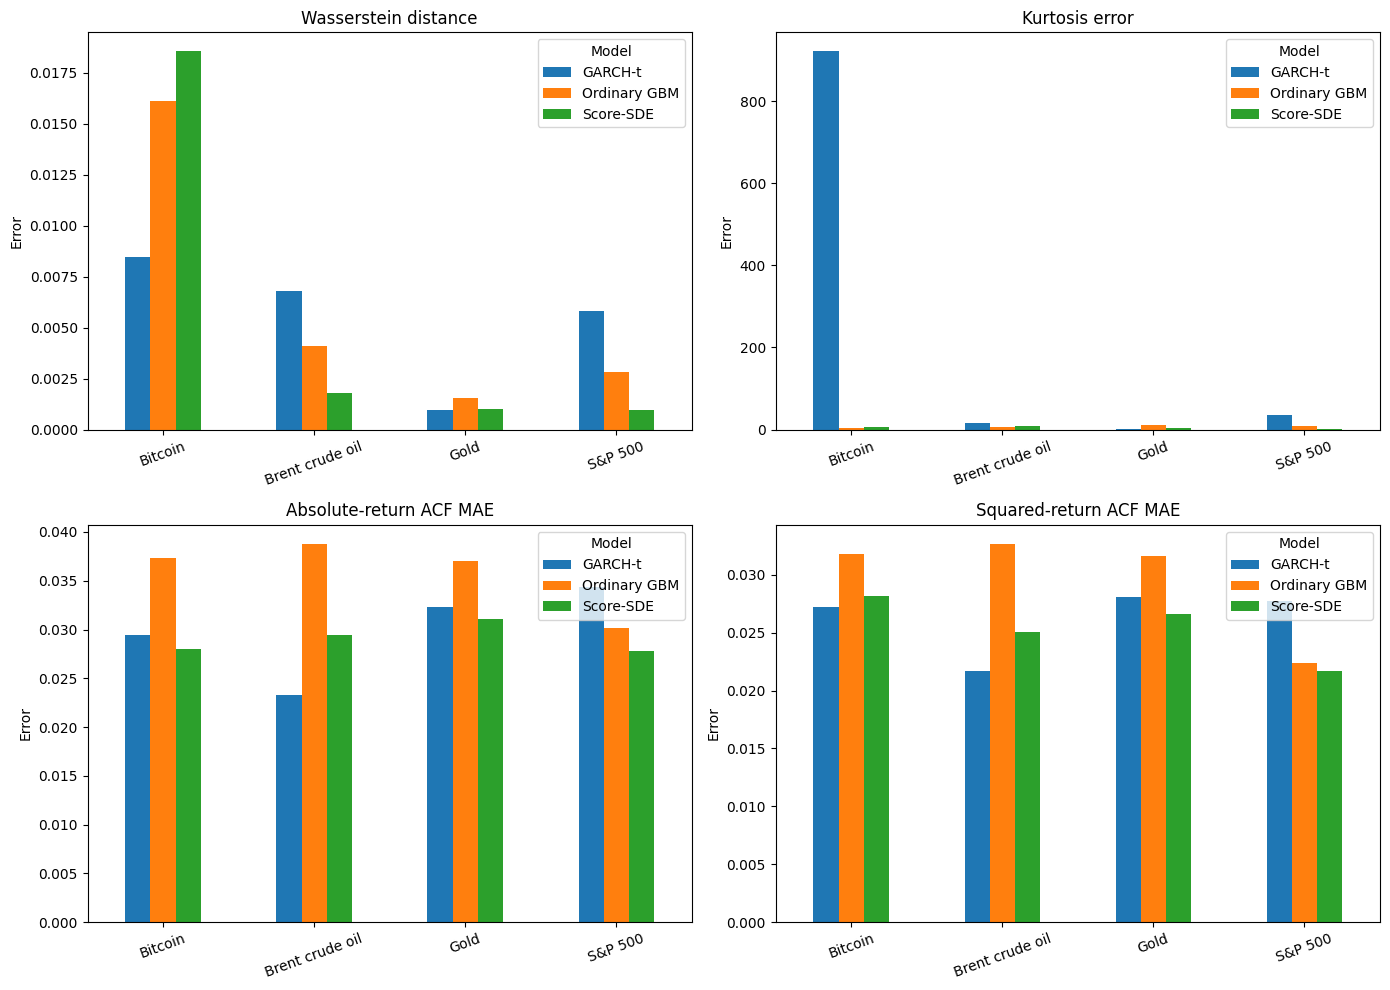

In [ ]:
plot_metrics = [
    "Wasserstein distance",
    "Kurtosis error",
    "Absolute-return ACF MAE",
    "Squared-return ACF MAE",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

plot_data = final_benchmark.reset_index()

for axis, metric in zip(axes, plot_metrics):
    pivot = plot_data.pivot(index="Asset", columns="Model", values=metric)
    pivot.plot(kind="bar", ax=axis)

    axis.set_title(metric)
    axis.set_xlabel("")
    axis.set_ylabel("Error")
    axis.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(results_dir / "25_final_benchmark_errors.png", dpi=300, bbox_inches="tight")  # save a 300 dpi dissertation figure
plt.show()

### Figure Note

*This figure summarises selected benchmark errors. The Bitcoin GARCH-t kurtosis error is extremely large, so the smaller kurtosis errors for the other asset-model combinations appear compressed on the same linear axis. The numerical benchmark table should therefore be used for exact comparisons.*

## 27. Final Cross-Asset Score-SDE Summary

Here I isolate the Score-SDE results so its performance can be compared directly across the four assets. This makes the main cross-asset conclusion easier to see: the model performs strongly for the S&P 500, gives mixed results for Gold and Brent, and performs poorly for Bitcoin.

In [ ]:
score_cross_asset = final_benchmark.xs("Score-SDE", level="Model").copy()  # isolate the score-sde rows for the cross-asset summary
display(score_cross_asset.round(6))
score_cross_asset.to_csv(results_dir / "26_score_sde_cross_asset_results.csv")  # save the numerical results as csv

,KS statistic,Wasserstein distance,Std error,Kurtosis error,VaR error,ES error,Absolute-return ACF MAE,Squared-return ACF MAE,Leverage MAE
Asset,,,,,,,,,
S&P 500,0.029988,0.000969,0.001373,1.473384,0.006034,0.009065,0.027796,0.021688,0.028421
Bitcoin,0.161280,0.018553,0.028430,5.475507,0.103006,0.138160,0.028033,0.028142,0.047697
Gold,0.046025,0.000993,0.001074,3.269361,0.002386,0.007479,0.031062,0.026654,0.028336
Brent crude oil,0.036444,0.001790,0.001495,7.772436,0.003723,0.013210,0.029421,0.025024,0.049107


### Cross-Asset Score-SDE Result

*The cross-asset table makes the main conclusion clear. The same Score-SDE setup does not transfer equally well to every market: the S&P 500 is the strongest case, Bitcoin is the weakest, and Gold and Brent lie between these two extremes depending on the measure being considered.*

## 28. Save the Final Dissertation Outputs

This final saving cell copies the generated arrays, result tables, figures and experiment settings into organised Google Drive folders. The figures have already been saved at 300 dpi, and the numerical tables are saved as CSV files so that they can be used directly in the dissertation.

In [ ]:
from shutil import copy2  # copy result files from the runtime folder to google drive

generated_dir = Path(SAVE_DIR) / "generated"  # store all generated return arrays together
generated_dir.mkdir(parents=True, exist_ok=True)  # create the generated-data folder if needed

tables_dir = Path(SAVE_DIR) / "tables"  # store all csv result tables together
tables_dir.mkdir(parents=True, exist_ok=True)  # create the table folder if needed

figures_dir = Path(SAVE_DIR) / "figures"  # store all saved dissertation figures together
figures_dir.mkdir(parents=True, exist_ok=True)  # create the figure folder if needed

for asset_name in assets:  # save every generated dataset for every asset
    safe_name = safe_asset_name(asset_name)  # create a simple file name

    np.save(  # save generated arrays for later use
        generated_dir / f"{safe_name}_return_space_ve_generated_returns.npy",
        return_ve_generated[asset_name],
    )  # save return-space ve artificial returns

    np.save(  # save generated arrays for later use
        generated_dir / f"{safe_name}_score_sde_generated_returns.npy",
        score_generated_returns[asset_name],
    )  # save final score-sde artificial returns

    np.save(  # save generated arrays for later use
        generated_dir / f"{safe_name}_gbm_generated_returns.npy",
        gbm_generated_returns[asset_name],
    )  # save ordinary gbm benchmark returns

    np.save(  # save generated arrays for later use
        generated_dir / f"{safe_name}_garch_t_generated_returns.npy",
        garch_generated_returns[asset_name],
    )  # save garch-t benchmark returns

for file_path in results_dir.glob("*.csv"):  # copy every final csv table to google drive
    copy2(file_path, tables_dir / file_path.name)  # keep the same table file name

for file_path in results_dir.glob("*.png"):  # copy every saved figure to google drive
    copy2(file_path, figures_dir / file_path.name)  # keep the same figure file name

settings_path = results_dir / "experiment_settings.json"  # locate the saved experiment settings

if settings_path.exists():  # save the settings file when it exists
    copy2(settings_path, Path(SAVE_DIR) / "experiment_settings.json")  # copy reproducibility settings to drive

print("saved model checkpoints to:", checkpoint_dir)  # show where trained model weights are stored
print("saved generated arrays to:", generated_dir)  # show where artificial series are stored
print("saved result tables to:", tables_dir)  # show where csv tables are stored
print("saved figures to:", figures_dir)  # show where dissertation figures are stored
print("all important dissertation outputs are now saved to google drive")  # confirm the saving step

saved model checkpoints to: /content/drive/MyDrive/dissertation_results/model_checkpoints
saved generated arrays to: /content/drive/MyDrive/dissertation_results/generated
saved result tables to: /content/drive/MyDrive/dissertation_results/tables
saved figures to: /content/drive/MyDrive/dissertation_results/figures
all important dissertation outputs are now saved to google drive


In [ ]:
# zip all dissertation results
!zip -r dissertation_results.zip /content/dissertation_results > /dev/null

# download the zip to your computer
from google.colab import files
files.download("/content/dissertation_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Saved Dissertation Files

*The final cell confirms that model checkpoints, generated arrays, CSV tables and the saved 300 dpi figures have been copied to Google Drive. These saved files are the ones to use when placing numerical results and plots into the dissertation.*

# Final Interpretation

The experiment should be interpreted across several diagnostics rather than from one statistic or one plot. The main questions are whether the generated data reproduce the return distribution and tail risk, whether they reproduce time-dependent volatility behaviour, and whether the relative log-price representation helps consistently across different asset classes.

The strongest Score-SDE result is for the S&P 500. Gold and Brent give mixed results depending on the measure. Bitcoin is the main failure case because the generated paths are systematically too volatile and have excessive downside tail risk. The representation comparison also shows that relative log prices are helpful for some assets but are not universally better than modelling returns directly.